01. DATA VISUALIZATION
Input file            : Chap10_Data.xlsx
Total samples         : 300
Valid hardness samples: 300
Target property       : Hv
Elemental features    : ['Al', 'Co', 'Cr', 'Cu', 'Fe', 'Ni']
Mean hardness         : 482.75 Hv
Median hardness       : 482.50 Hv


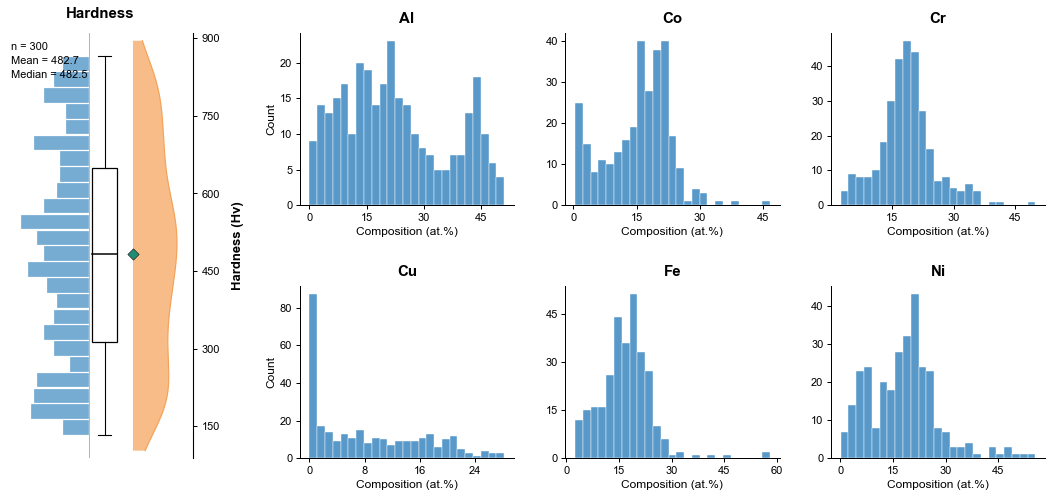


Visualization completed successfully.
Saved figure: 01_Data_Distribution.png


In [1]:
# ============================================================
# 01. DATA VISUALIZATION
# Hardness and Elemental Composition Distributions
#
# Input:
#   Chap10_Data.xlsx
#
# Output:
#   01_Data_Distribution.png
#
# Description:
#   - Hardness: Histogram + Boxplot + Half-Violin
#   - Compositions: Histograms for six elements
#   - Nature-style visualization
#   - High-resolution PNG (600 dpi)
# ============================================================

# ------------------------------------------------------------
# 1. Import Libraries
# ------------------------------------------------------------

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from matplotlib import gridspec
from matplotlib.ticker import MaxNLocator
from scipy.stats import gaussian_kde


# ------------------------------------------------------------
# 2. General Settings
# ------------------------------------------------------------

INPUT_FILE = "Chap10_Data.xlsx"
OUTPUT_FILE = "01_Data_Distribution.png"

DPI = 600

# True: convert atomic fractions (0–1) to at.%
# False: compositions are already expressed in at.%
CONVERT_TO_AT_PERCENT = True

# Figure size: approximately 16:9
FIG_SIZE = (15.5, 7.2)

# Color palette
BLUE = "#4F94C6"
ORANGE = "#F4A259"
GREEN = "#218C74"

# Matplotlib style
plt.rcParams.update({
    "font.family": "Arial",
    "font.size": 12,
    "axes.labelsize": 13,
    "axes.titlesize": 15,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "axes.linewidth": 1.1,
    "xtick.direction": "out",
    "ytick.direction": "out",
    "xtick.major.size": 4,
    "ytick.major.size": 4,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.dpi": DPI
})


# ------------------------------------------------------------
# 3. Load Dataset
# ------------------------------------------------------------

df = pd.read_excel(INPUT_FILE)

# Dataset structure:
# Column 1: Vickers hardness (Hv)
# Columns 2–7: Elemental compositions

hardness_col = df.columns[0]
element_cols = list(df.columns[1:7])

if len(element_cols) != 6:
    raise ValueError(
        "The dataset must contain six elemental "
        "composition columns after hardness."
    )

# Extract relevant numerical data
data = df[[hardness_col] + element_cols].apply(
    pd.to_numeric,
    errors="coerce"
)

hardness = data[hardness_col].dropna()
hv = hardness.to_numpy()

if len(hv) == 0:
    raise ValueError("No valid hardness values found.")

# Convert atomic fractions to atomic percentages
if CONVERT_TO_AT_PERCENT:
    data.loc[:, element_cols] = (
        data[element_cols] * 100
    )

# Basic statistical information
mean_hv = np.mean(hv)
median_hv = np.median(hv)
hv_range = np.ptp(hv)

print("=" * 60)
print("01. DATA VISUALIZATION")
print("=" * 60)

print(f"Input file            : {INPUT_FILE}")
print(f"Total samples         : {len(df)}")
print(f"Valid hardness samples: {len(hv)}")
print(f"Target property       : {hardness_col}")
print(f"Elemental features    : {element_cols}")
print(f"Mean hardness         : {mean_hv:.2f} Hv")
print(f"Median hardness       : {median_hv:.2f} Hv")

print("=" * 60)


# ------------------------------------------------------------
# 4. Create Figure Layout
# ------------------------------------------------------------

fig = plt.figure(
    figsize=FIG_SIZE,
    facecolor="white"
)

# Left: Hardness distribution
# Right: Six elemental composition histograms

outer = gridspec.GridSpec(
    nrows=1,
    ncols=2,
    width_ratios=[1.12, 4.5],
    wspace=0.23,
    left=0.055,
    right=0.985,
    bottom=0.12,
    top=0.94
)

ax_h = fig.add_subplot(
    outer[0, 0]
)

right_grid = gridspec.GridSpecFromSubplotSpec(
    2,
    3,
    subplot_spec=outer[0, 1],
    wspace=0.24,
    hspace=0.47
)


# ------------------------------------------------------------
# 5. Hardness Distribution
# ------------------------------------------------------------

# 5.1 Horizontal histogram

counts, edges = np.histogram(
    hv,
    bins=24
)

hist_width = 0.43

scaled_counts = (
    counts / max(counts.max(), 1) * hist_width
)

bin_centers = (
    edges[:-1] + edges[1:]
) / 2

bin_heights = np.diff(edges)

ax_h.barh(
    bin_centers,
    scaled_counts,
    height=bin_heights * 0.92,
    left=-scaled_counts,
    color=BLUE,
    alpha=0.78,
    edgecolor="white",
    linewidth=0.35,
    zorder=2
)


# 5.2 Central boxplot

ax_h.boxplot(
    hv,
    positions=[0.10],
    widths=0.16,
    vert=True,
    patch_artist=True,
    showfliers=False,

    boxprops={
        "facecolor": "white",
        "edgecolor": "black",
        "linewidth": 1.25
    },

    medianprops={
        "color": "black",
        "linewidth": 1.5
    },

    whiskerprops={
        "color": "black",
        "linewidth": 1.1
    },

    capprops={
        "color": "black",
        "linewidth": 1.1
    },

    zorder=4
)


# 5.3 Half-violin plot

violin_center = 0.28
violin_width = 0.28

if len(hv) >= 2 and np.std(hv) > 0:

    kde = gaussian_kde(
        hv,
        bw_method="scott"
    )

    y_min = hv.min() - 0.04 * hv_range
    y_max = hv.max() + 0.04 * hv_range

    y_grid = np.linspace(
        y_min,
        y_max,
        500
    )

    density = kde(y_grid)

    density = (
        density / density.max() * violin_width
    )

    # Right-facing half-violin
    ax_h.fill_betweenx(
        y_grid,
        violin_center,
        violin_center + density,
        facecolor=ORANGE,
        edgecolor="none",
        alpha=0.72,
        zorder=3
    )

    # Smooth outer boundary
    ax_h.plot(
        violin_center + density,
        y_grid,
        color=ORANGE,
        linewidth=1.2,
        zorder=4
    )


# 5.4 Mean hardness marker

ax_h.scatter(
    violin_center,
    mean_hv,
    s=65,
    marker="D",
    color=GREEN,
    edgecolor="black",
    linewidth=0.5,
    zorder=6
)


# 5.5 Histogram baseline

ax_h.axvline(
    0,
    color="gray",
    linewidth=0.9,
    alpha=0.65,
    zorder=1
)


# 5.6 Statistical annotation

stats_text = (
    f"n = {len(hv)}\n"
    f"Mean = {mean_hv:.1f}\n"
    f"Median = {median_hv:.1f}"
)

ax_h.text(
    0.02,
    0.98,
    stats_text,
    transform=ax_h.transAxes,
    ha="left",
    va="top",
    fontsize=11,
    color="black",
    linespacing=1.5,
    zorder=10
)


# ------------------------------------------------------------
# 6. Format Hardness Axis
# ------------------------------------------------------------

ax_h.set_xlim(
    -0.52,
    0.66
)

# Add vertical margins around hardness values
vertical_padding = max(
    0.06 * hv_range,
    1.0
)

ax_h.set_ylim(
    hv.min() - vertical_padding,
    hv.max() + vertical_padding
)

ax_h.set_title(
    "Hardness",
    fontsize=15,
    fontweight="bold",
    pad=15
)

ax_h.set_xticks([])

# Display hardness axis on the right
ax_h.yaxis.tick_right()
ax_h.yaxis.set_label_position("right")

ax_h.set_ylabel(
    "Hardness (Hv)",
    fontsize=13,
    fontweight="bold",
    labelpad=12
)

ax_h.yaxis.set_major_locator(
    MaxNLocator(nbins=6)
)

# Hide unnecessary spines
for spine in ["left", "top", "bottom"]:
    ax_h.spines[spine].set_visible(False)

# Keep right-side hardness axis visible
ax_h.spines["right"].set_visible(True)
ax_h.spines["right"].set_color("black")
ax_h.spines["right"].set_linewidth(1.1)

ax_h.tick_params(
    axis="y",
    right=True,
    left=False,
    labelright=True,
    labelleft=False,
    direction="out",
    length=4,
    width=1.0,
    pad=5
)


# ------------------------------------------------------------
# 7. Elemental Composition Distributions
# ------------------------------------------------------------

for i, element in enumerate(element_cols):

    row = i // 3
    col = i % 3

    ax = fig.add_subplot(
        right_grid[row, col]
    )

    values = (
        data[element]
        .dropna()
        .to_numpy()
    )

    ax.hist(
        values,
        bins=25,
        color=BLUE,
        alpha=0.95,
        edgecolor="white",
        linewidth=0.45
    )

    # Element symbol as subplot title
    ax.set_title(
        str(element),
        fontsize=15,
        fontweight="bold",
        pad=10
    )

    ax.set_xlabel(
        "Composition (at.%)",
        fontsize=12
    )

    if col == 0:
        ax.set_ylabel(
            "Count",
            fontsize=12
        )

    ax.yaxis.set_major_locator(
        MaxNLocator(
            nbins=5,
            integer=True
        )
    )

    ax.xaxis.set_major_locator(
        MaxNLocator(nbins=5)
    )

    # Nature-style formatting
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    ax.spines["left"].set_linewidth(1.0)
    ax.spines["bottom"].set_linewidth(1.0)

    ax.tick_params(
        axis="both",
        direction="out",
        length=4,
        width=1.0
    )

    ax.grid(False)


# ------------------------------------------------------------
# 8. Save and Display
# ------------------------------------------------------------

fig.savefig(
    OUTPUT_FILE,
    dpi=DPI,
    facecolor="white"
)

plt.show()
plt.close(fig)


# ------------------------------------------------------------
# 9. Summary
# ------------------------------------------------------------

print("\nVisualization completed successfully.")
print(f"Saved figure: {OUTPUT_FILE}")

C:\Users\Libin Zhang\anaconda3\envs\pytorch\lib\site-packages\tqdm\auto.py:22: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


02. UMAP VISUALIZATION
Input file         : Chap10_Data.xlsx
Valid samples      : 300
Hardness column    : Hv
Element columns    : ['Al', 'Co', 'Cr', 'Cu', 'Fe', 'Ni']
UMAP n_neighbors   : 20
UMAP min_dist      : 0.15
UMAP metric        : euclidean


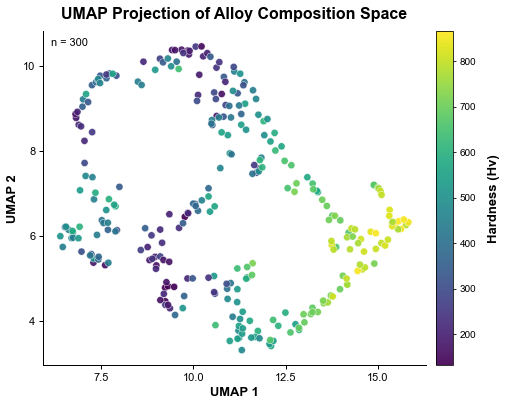


Visualization completed successfully.
Saved figure: 02_UMAP_Projection.png


In [2]:
# ============================================================
# 02. DATA VISUALIZATION
# UMAP Projection of Alloy Composition Space
#
# Input:
#   Chap10_Data.xlsx
#
# Output:
#   02_UMAP_Projection.png
#
# Description:
#   - Use six elemental compositions as input features
#   - Reduce the composition space to 2D using UMAP
#   - Color points by Vickers hardness (Hv)
# ============================================================

# ------------------------------------------------------------
# 1. Import Libraries
# ------------------------------------------------------------

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from matplotlib.colors import Normalize
from matplotlib.ticker import MaxNLocator
from sklearn.preprocessing import StandardScaler

# If needed, install with:
# !pip install umap-learn

import umap.umap_ as umap

# ------------------------------------------------------------
# 2. General Settings
# ------------------------------------------------------------

INPUT_FILE = "Chap10_Data.xlsx"
OUTPUT_FILE = "02_UMAP_Projection.png"

DPI = 600
RANDOM_STATE = 42

# UMAP parameters
N_COMPONENTS = 2
N_NEIGHBORS = 20
MIN_DIST = 0.15
METRIC = "euclidean"

# Figure size
FIG_SIZE = (7.2, 5.8)

plt.rcParams.update({
    "font.family": "Arial",
    "font.size": 12,
    "axes.labelsize": 13,
    "axes.titlesize": 16,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "axes.linewidth": 1.1,
    "xtick.direction": "out",
    "ytick.direction": "out",
    "xtick.major.size": 4,
    "ytick.major.size": 4,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.dpi": DPI
})

# ------------------------------------------------------------
# 3. Load Dataset
# ------------------------------------------------------------

df = pd.read_excel(INPUT_FILE)

# Dataset structure:
# Column 1: Hardness (Hv)
# Columns 2–7: Elemental compositions

hardness_col = df.columns[0]
element_cols = list(df.columns[1:7])

if len(element_cols) != 6:
    raise ValueError(
        "The dataset must contain six elemental "
        "composition columns after hardness."
    )

# Keep only hardness and elemental composition columns
data = df[[hardness_col] + element_cols].apply(
    pd.to_numeric,
    errors="coerce"
)

# Remove rows with missing values in required columns
data = data.dropna(
    subset=[hardness_col] + element_cols
).reset_index(drop=True)

if len(data) == 0:
    raise ValueError("No valid samples found after removing missing values.")

# Input features: elemental compositions
X = data[element_cols].to_numpy()

# Target for color mapping: hardness
y = data[hardness_col].to_numpy()

print("=" * 60)
print("02. UMAP VISUALIZATION")
print("=" * 60)

print(f"Input file         : {INPUT_FILE}")
print(f"Valid samples      : {len(data)}")
print(f"Hardness column    : {hardness_col}")
print(f"Element columns    : {element_cols}")
print(f"UMAP n_neighbors   : {N_NEIGHBORS}")
print(f"UMAP min_dist      : {MIN_DIST}")
print(f"UMAP metric        : {METRIC}")

print("=" * 60)

# ------------------------------------------------------------
# 4. Feature Scaling
# ------------------------------------------------------------

# Standardization is recommended before UMAP
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# ------------------------------------------------------------
# 5. UMAP Dimensionality Reduction
# ------------------------------------------------------------

reducer = umap.UMAP(
    n_components=N_COMPONENTS,
    n_neighbors=N_NEIGHBORS,
    min_dist=MIN_DIST,
    metric=METRIC,
    random_state=RANDOM_STATE
)

embedding = reducer.fit_transform(X_scaled)

# ------------------------------------------------------------
# 6. Create Figure
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=FIG_SIZE,
    facecolor="white"
)

# Color normalization based on hardness
norm = Normalize(
    vmin=np.min(y),
    vmax=np.max(y)
)

# Scatter plot
sc = ax.scatter(
    embedding[:, 0],
    embedding[:, 1],
    c=y,
    cmap="viridis",
    norm=norm,
    s=52,
    alpha=0.92,
    edgecolors="white",
    linewidths=0.45
)

# ------------------------------------------------------------
# 7. Figure Formatting
# ------------------------------------------------------------

ax.set_title(
    "UMAP Projection of Alloy Composition Space",
    pad=12,
    fontweight="bold"
)

ax.set_xlabel(
    "UMAP 1",
    fontweight="bold"
)

ax.set_ylabel(
    "UMAP 2",
    fontweight="bold"
)

# Clean axis formatting
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_linewidth(1.0)
ax.spines["bottom"].set_linewidth(1.0)

ax.tick_params(
    axis="both",
    direction="out",
    length=4,
    width=1.0
)

ax.xaxis.set_major_locator(
    MaxNLocator(nbins=5)
)

ax.yaxis.set_major_locator(
    MaxNLocator(nbins=5)
)

# Sample count annotation
ax.text(
    0.02,
    0.98,
    f"n = {len(y)}",
    transform=ax.transAxes,
    ha="left",
    va="top",
    fontsize=11
)

# ------------------------------------------------------------
# 8. Colorbar
# ------------------------------------------------------------

cbar = fig.colorbar(
    sc,
    ax=ax,
    pad=0.025,
    fraction=0.05
)

cbar.set_label(
    "Hardness (Hv)",
    rotation=90,
    labelpad=12,
    fontweight="bold"
)

cbar.ax.tick_params(
    labelsize=10,
    width=0.8,
    length=3
)

cbar.outline.set_linewidth(0.8)

# ------------------------------------------------------------
# 9. Save and Display
# ------------------------------------------------------------

plt.tight_layout()

fig.savefig(
    OUTPUT_FILE,
    dpi=DPI,
    facecolor="white",
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# ------------------------------------------------------------
# 10. Summary
# ------------------------------------------------------------

print("\nVisualization completed successfully.")
print(f"Saved figure: {OUTPUT_FILE}")

03. MODEL COMPARISON
Input file       : Chap10_Data.xlsx
Total samples    : 300
Training samples : 240
Testing samples  : 60
Input features   : 72
Target property  : Hv
CV folds         : 5
Evaluating GDB ...
Evaluating RF ...
Evaluating XGB ...
Evaluating ADB ...
Evaluating DT ...
Evaluating SVM-lin ...
Evaluating SVM-poly ...
Evaluating SVM-rbf ...
Evaluating KNN ...
Evaluating MLP ...

MODEL PERFORMANCE SUMMARY
   Model  CV_R2_Mean  CV_RMSE_Mean  CV_MAE_Mean  Recommended
     GDB      0.9007       62.0757      47.7231        False
      RF      0.9088       59.3724      46.8195         True
     XGB      0.8912       64.8370      49.2139        False
     ADB      0.9006       62.1638      48.6970        False
      DT      0.8408       78.9023      61.1875        False
 SVM-lin      0.8997       62.5296      47.6861        False
SVM-poly      0.5885      126.5015     107.6553        False
 SVM-rbf      0.1726      180.0067     150.6928        False
     KNN      0.8994       62.406

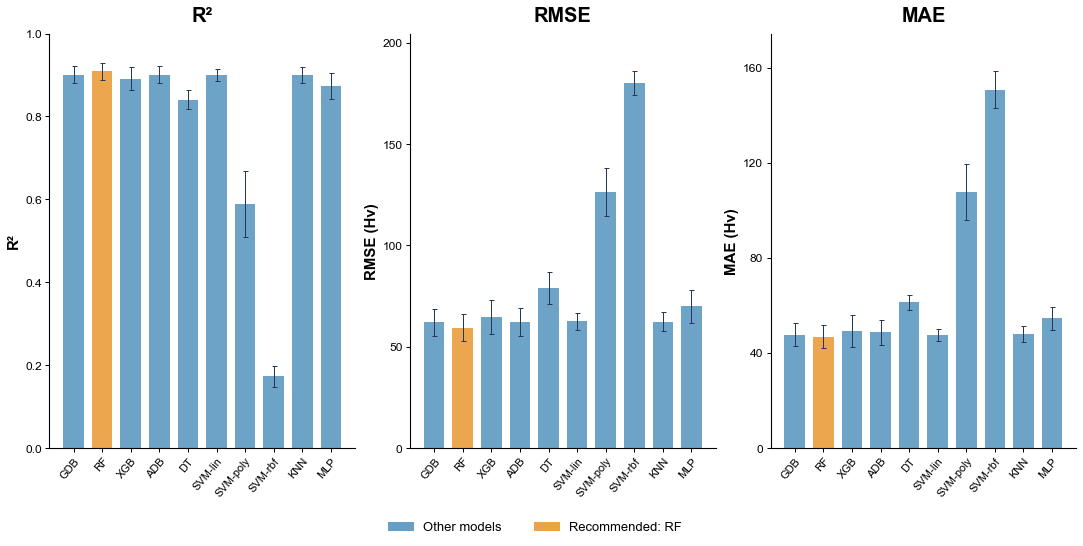


MODEL COMPARISON COMPLETED
Recommended model: RF

Saved files:
1. 03_Model_Comparison_Performance.png
2. 03_Model_Comparison_Results.xlsx


In [3]:

# ============================================================
# 03. MODEL COMPARISON
# Performance Evaluation of 10 Machine Learning Algorithms
#
# Input:
#   Chap10_Data.xlsx
#
# Outputs:
#   03_Model_Comparison_Performance.png
#   03_Model_Comparison_Results.xlsx
#
# Description:
#   - Compare 10 regression algorithms
#   - Use 80/20 train-test splitting
#   - Evaluate models using 5-fold cross-validation
#   - Compare R2, RMSE, and MAE
#   - Select the best model based on mean CV R2
# ============================================================

# ------------------------------------------------------------
# 1. Import Libraries
# ------------------------------------------------------------

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from matplotlib.patches import Patch
from matplotlib.ticker import MaxNLocator

from sklearn.model_selection import (
    train_test_split,
    KFold,
    cross_validate
)

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

from sklearn.ensemble import (
    GradientBoostingRegressor,
    RandomForestRegressor,
    AdaBoostRegressor
)

from sklearn.tree import DecisionTreeRegressor
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from sklearn.neural_network import MLPRegressor

from sklearn.metrics import (
    r2_score,
    mean_squared_error,
    mean_absolute_error
)

from xgboost import XGBRegressor


# ------------------------------------------------------------
# 2. General Settings
# ------------------------------------------------------------

INPUT_FILE = "Chap10_Data.xlsx"

FIGURE_FILE = "03_Model_Comparison_Performance.png"
EXCEL_FILE = "03_Model_Comparison_Results.xlsx"

RANDOM_STATE = 42
TEST_SIZE = 0.20
CV_FOLDS = 5

N_JOBS = -1
DPI = 600

# Figure settings
FIG_SIZE = (15.5, 8.72)

# Colors
BLUE = "#669FC5"
ORANGE = "#EBA347"
DARK_BLUE = "#243956"

plt.rcParams.update({
    "font.family": "Arial",
    "font.size": 13,
    "axes.labelsize": 15,
    "axes.titlesize": 18,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "axes.linewidth": 1.1,
    "xtick.direction": "out",
    "ytick.direction": "out",
    "xtick.major.size": 5,
    "ytick.major.size": 4,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.dpi": DPI
})


# ------------------------------------------------------------
# 3. Load Dataset
# ------------------------------------------------------------

df = pd.read_excel(INPUT_FILE)

# First column: Vickers hardness (Hv)
# Remaining columns: Input features

target_col = df.columns[0]
feature_cols = list(df.columns[1:])

# Convert data to numerical values
y_all = pd.to_numeric(
    df[target_col],
    errors="coerce"
)

X_all = df[feature_cols].apply(
    pd.to_numeric,
    errors="coerce"
)

X_all = X_all.replace(
    [np.inf, -np.inf],
    np.nan
)

# Remove samples with missing hardness
valid_mask = y_all.notna()

X = X_all.loc[valid_mask].copy()
y = y_all.loc[valid_mask].copy()

if len(X) < 20:
    raise ValueError(
        "Insufficient samples for model comparison."
    )


# ------------------------------------------------------------
# 4. Train-Test Split
# ------------------------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE
)

# Remove features that are entirely missing
# in the training set.
valid_features = X_train.columns[
    X_train.notna().any(axis=0)
].tolist()

if not valid_features:
    raise ValueError(
        "No usable input features were found."
    )

X_train = X_train[valid_features]
X_test = X_test[valid_features]

print("=" * 65)
print("03. MODEL COMPARISON")
print("=" * 65)

print(f"Input file       : {INPUT_FILE}")
print(f"Total samples    : {len(X)}")
print(f"Training samples : {len(X_train)}")
print(f"Testing samples  : {len(X_test)}")
print(f"Input features   : {len(valid_features)}")
print(f"Target property  : {target_col}")
print(f"CV folds         : {CV_FOLDS}")

print("=" * 65)


# ------------------------------------------------------------
# 5. Initialize Machine Learning Models
# ------------------------------------------------------------

# Keep a fixed model order for comparison.

models = {

    # Tree-based models
    "GDB": GradientBoostingRegressor(
        random_state=RANDOM_STATE
    ),

    "RF": RandomForestRegressor(
        n_estimators=300,
        random_state=RANDOM_STATE,
        n_jobs=1
    ),

    "XGB": XGBRegressor(
        n_estimators=300,
        objective="reg:squarederror",
        random_state=RANDOM_STATE,
        n_jobs=1,
        verbosity=0
    ),

    "ADB": AdaBoostRegressor(
        n_estimators=100,
        random_state=RANDOM_STATE
    ),

    "DT": DecisionTreeRegressor(
        random_state=RANDOM_STATE
    ),

    # Support Vector Machines
    "SVM-lin": SVR(kernel="linear"),
    "SVM-poly": SVR(kernel="poly"),
    "SVM-rbf": SVR(kernel="rbf"),

    # Instance-based model
    "KNN": KNeighborsRegressor(
        n_neighbors=5
    ),

    # Neural network
    "MLP": MLPRegressor(
        hidden_layer_sizes=(64, 32),
        activation="relu",
        solver="adam",
        max_iter=3000,
        early_stopping=True,
        random_state=RANDOM_STATE
    )
}

MODEL_ORDER = list(models.keys())


# ------------------------------------------------------------
# 6. Build Preprocessing Pipelines
# ------------------------------------------------------------

# Scaling is applied only when required.

SCALE_MODELS = {
    "SVM-lin",
    "SVM-poly",
    "SVM-rbf",
    "KNN",
    "MLP"
}

pipelines = {}

for name, model in models.items():

    steps = [
        ("imputer", SimpleImputer(strategy="median"))
    ]

    if name in SCALE_MODELS:
        steps.append(
            ("scaler", StandardScaler())
        )

    steps.append(
        ("model", model)
    )

    pipelines[name] = Pipeline(steps)


# ------------------------------------------------------------
# 7. Cross-Validation Settings
# ------------------------------------------------------------

cv = KFold(
    n_splits=CV_FOLDS,
    shuffle=True,
    random_state=RANDOM_STATE
)

scoring = {
    "R2": "r2",
    "RMSE": "neg_root_mean_squared_error",
    "MAE": "neg_mean_absolute_error"
}


# ------------------------------------------------------------
# 8. Train and Evaluate Models
# ------------------------------------------------------------

model_results = []
fold_results = []

for name in MODEL_ORDER:

    pipeline = pipelines[name]

    print(f"Evaluating {name} ...")

    # 8.1 Cross-validation on training data
    cv_results = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=N_JOBS,
        error_score="raise"
    )

    cv_r2 = cv_results["test_R2"]
    cv_rmse = -cv_results["test_RMSE"]
    cv_mae = -cv_results["test_MAE"]

    # Store individual fold results
    for fold_idx in range(CV_FOLDS):

        fold_results.append({
            "Model": name,
            "Fold": fold_idx + 1,
            "R2": cv_r2[fold_idx],
            "RMSE": cv_rmse[fold_idx],
            "MAE": cv_mae[fold_idx]
        })

    # 8.2 Train model on the full training set
    pipeline.fit(X_train, y_train)

    train_pred = pipeline.predict(X_train)
    test_pred = pipeline.predict(X_test)

    # 8.3 Calculate training and testing metrics
    train_r2 = r2_score(y_train, train_pred)

    train_rmse = np.sqrt(
        mean_squared_error(y_train, train_pred)
    )

    train_mae = mean_absolute_error(
        y_train, train_pred
    )

    test_r2 = r2_score(y_test, test_pred)

    test_rmse = np.sqrt(
        mean_squared_error(y_test, test_pred)
    )

    test_mae = mean_absolute_error(
        y_test, test_pred
    )

    # 8.4 Store model performance
    model_results.append({
        "Model": name,

        "Train_R2": train_r2,
        "Train_RMSE": train_rmse,
        "Train_MAE": train_mae,

        "CV_R2_Mean": np.mean(cv_r2),
        "CV_R2_STD": np.std(cv_r2, ddof=1),

        "CV_RMSE_Mean": np.mean(cv_rmse),
        "CV_RMSE_STD": np.std(cv_rmse, ddof=1),

        "CV_MAE_Mean": np.mean(cv_mae),
        "CV_MAE_STD": np.std(cv_mae, ddof=1),

        "Test_R2": test_r2,
        "Test_RMSE": test_rmse,
        "Test_MAE": test_mae
    })


# ------------------------------------------------------------
# 9. Select the Best-Performing Model
# ------------------------------------------------------------

performance_df = pd.DataFrame(model_results)

# Preserve the original model order
performance_df = (
    performance_df
    .set_index("Model")
    .loc[MODEL_ORDER]
    .reset_index()
)

# Select the model with the highest mean CV R2.
# Test performance is NOT used for model selection.

best_idx = performance_df["CV_R2_Mean"].idxmax()

recommended_model = performance_df.loc[
    best_idx, "Model"
]

performance_df["Recommended"] = (
    performance_df["Model"] == recommended_model
)

best_row = performance_df.loc[best_idx]

# Store the recommended model and settings
best_model_df = pd.DataFrame([{
    "Model": recommended_model,
    "Selection_Criterion": "Highest mean 5-fold CV R2",

    "CV_R2_Mean": best_row["CV_R2_Mean"],
    "CV_R2_STD": best_row["CV_R2_STD"],
    "CV_RMSE_Mean": best_row["CV_RMSE_Mean"],
    "CV_MAE_Mean": best_row["CV_MAE_Mean"],

    "Test_R2": best_row["Test_R2"],
    "Test_RMSE": best_row["Test_RMSE"],
    "Test_MAE": best_row["Test_MAE"],

    "Random_State": RANDOM_STATE,
    "Test_Size": TEST_SIZE,
    "CV_Folds": CV_FOLDS,
    "Number_of_Features": len(valid_features)
}])

fold_df = pd.DataFrame(fold_results)

print("\n" + "=" * 65)
print("MODEL PERFORMANCE SUMMARY")
print("=" * 65)

print(
    performance_df[
        [
            "Model",
            "CV_R2_Mean",
            "CV_RMSE_Mean",
            "CV_MAE_Mean",
            "Recommended"
        ]
    ].round(4).to_string(index=False)
)

print("\nRecommended model:", recommended_model)
print(f"Mean CV R2: {best_row['CV_R2_Mean']:.4f}")


# ------------------------------------------------------------
# 10. Save Excel Results
# ------------------------------------------------------------

with pd.ExcelWriter(
    EXCEL_FILE,
    engine="openpyxl"
) as writer:

    # All model performance metrics
    performance_df.to_excel(
        writer,
        sheet_name="Model_Performance",
        index=False
    )

    # Recommended model and evaluation settings
    best_model_df.to_excel(
        writer,
        sheet_name="Best_Model",
        index=False
    )

    # Individual cross-validation folds
    fold_df.to_excel(
        writer,
        sheet_name="CV_Fold_Results",
        index=False
    )

    # Format Excel sheets
    for sheet in writer.sheets.values():

        sheet.freeze_panes = "B2"
        sheet.auto_filter.ref = sheet.dimensions

        for column_cells in sheet.columns:

            max_length = max(
                len(str(cell.value))
                if cell.value is not None else 0
                for cell in column_cells
            )

            column_letter = (
                column_cells[0].column_letter
            )

            sheet.column_dimensions[
                column_letter
            ].width = min(max_length + 3, 40)

print(f"\nExcel results saved: {EXCEL_FILE}")


# ------------------------------------------------------------
# 11. Model Comparison Visualization
# ------------------------------------------------------------

model_names = performance_df["Model"].to_numpy()
x = np.arange(len(model_names))

# Highlight the recommended model
bar_colors = [
    ORANGE if name == recommended_model else BLUE
    for name in model_names
]

metrics = [
    {
        "title": "R²",
        "mean": "CV_R2_Mean",
        "std": "CV_R2_STD",
        "ylabel": "R²"
    },
    {
        "title": "RMSE",
        "mean": "CV_RMSE_Mean",
        "std": "CV_RMSE_STD",
        "ylabel": "RMSE (Hv)"
    },
    {
        "title": "MAE",
        "mean": "CV_MAE_Mean",
        "std": "CV_MAE_STD",
        "ylabel": "MAE (Hv)"
    }
]

fig, axes = plt.subplots(
    1, 3,
    figsize=FIG_SIZE
)

for ax, metric in zip(axes, metrics):

    values = performance_df[
        metric["mean"]
    ].to_numpy(dtype=float)

    errors = performance_df[
        metric["std"]
    ].to_numpy(dtype=float)

    # 11.1 Performance bars
    ax.bar(
        x,
        values,
        width=0.72,
        color=bar_colors,
        edgecolor="none",
        alpha=0.96,
        zorder=2
    )

    # 11.2 Cross-validation standard deviation
    ax.errorbar(
        x,
        values,
        yerr=errors,
        fmt="none",
        ecolor=DARK_BLUE,
        elinewidth=1.0,
        capsize=2.5,
        capthick=1.0,
        zorder=3
    )

    # 11.3 Titles and labels
    ax.set_title(
        metric["title"],
        fontsize=20,
        fontweight="bold",
        pad=12
    )

    ax.set_xticks(x)

    ax.set_xticklabels(
        model_names,
        rotation=50,
        ha="right",
        rotation_mode="anchor",
        fontsize=11
    )

    ax.set_ylabel(
        metric["ylabel"],
        fontsize=15,
        fontweight="bold"
    )

    ax.yaxis.set_major_locator(
        MaxNLocator(nbins=5)
    )

    # 11.4 Axis limits
    lower = values - errors
    upper = values + errors

    if metric["title"] == "R²":

        y_min = min(
            0,
            float(np.min(lower)) - 0.03
        )

        y_max = max(
            1.0,
            float(np.max(upper)) + 0.03
        )

        ax.set_ylim(y_min, y_max)

    else:

        ax.set_ylim(
            0,
            float(np.max(upper)) * 1.10
        )

    # 11.5 Axis formatting
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    ax.spines["left"].set_linewidth(1.1)
    ax.spines["bottom"].set_linewidth(1.1)

    ax.tick_params(
        axis="both",
        direction="out",
        length=4,
        width=1.0
    )

    ax.grid(False)


# ------------------------------------------------------------
# 12. Shared Legend
# ------------------------------------------------------------

legend_elements = [
    Patch(
        facecolor=BLUE,
        label="Other models"
    ),
    Patch(
        facecolor=ORANGE,
        label=f"Recommended: {recommended_model}"
    )
]

fig.legend(
    handles=legend_elements,
    loc="lower center",
    bbox_to_anchor=(0.5, 0.085),
    ncol=2,
    frameon=False,
    fontsize=13,
    columnspacing=2.5,
    handletextpad=0.7
)


# ------------------------------------------------------------
# 13. Figure Layout and Saving
# ------------------------------------------------------------

fig.subplots_adjust(
    left=0.065,
    right=0.985,
    bottom=0.24,
    top=0.90,
    wspace=0.18
)

fig.savefig(
    FIGURE_FILE,
    dpi=DPI,
    facecolor="white"
)

plt.show()
plt.close(fig)


# ------------------------------------------------------------
# 14. Final Summary
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("MODEL COMPARISON COMPLETED")
print("=" * 65)

print(f"Recommended model: {recommended_model}")

print("\nSaved files:")
print(f"1. {FIGURE_FILE}")
print(f"2. {EXCEL_FILE}")

print("=" * 65)

04. PCC CORRELATION ANALYSIS
Input file        : Chap10_Data.xlsx
Model settings    : 03_Model_Comparison_Results.xlsx
Random state      : 42
Test size         : 0.2
PCC threshold     : 0.95

Dataset information:
Total samples      : 300
Training samples   : 240
Testing samples    : 60
Valid features     : 72

Excel results saved: 04_PCC_Correlation_Matrix.xlsx


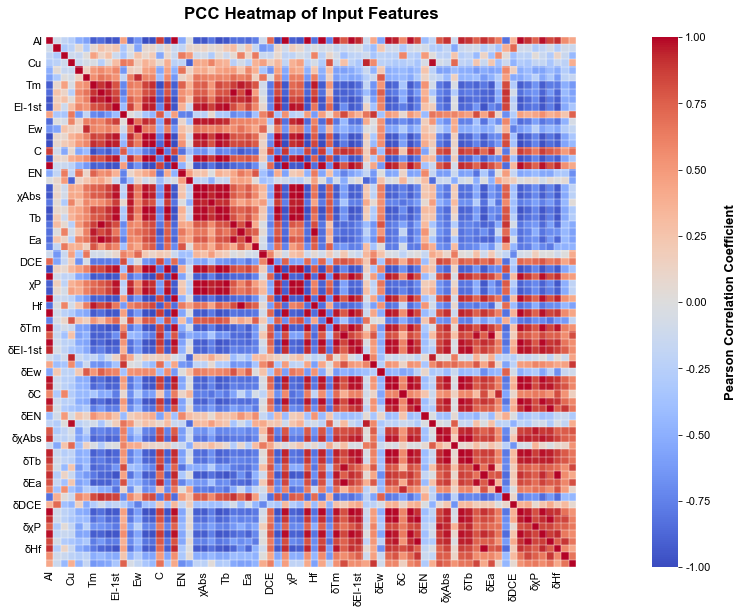


PCC CORRELATION ANALYSIS COMPLETED
Number of features: 72
Highly correlated pairs (|PCC| > 0.95): 249

Saved files:
1. 04_PCC_Correlation_Matrix.xlsx
2. 04_PCC_Correlation_Heatmap.png


In [4]:
# ============================================================
# 04. FEATURE ENGINEERING - PCC CORRELATION ANALYSIS
# Pearson Correlation Coefficient (PCC) Heatmap
#
# Inputs:
#   Chap10_Data.xlsx
#   03_Model_Comparison_Results.xlsx
#
# Outputs:
#   04_PCC_Correlation_Matrix.xlsx
#   04_PCC_Correlation_Heatmap.png
#
# Description:
#   - Calculate pairwise Pearson correlations
#   - Identify highly correlated feature pairs
#   - Visualize the complete PCC matrix
#   - Use training data only to prevent test data leakage
# ============================================================

# ------------------------------------------------------------
# 1. Import Libraries
# ------------------------------------------------------------

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from matplotlib.colors import TwoSlopeNorm
from matplotlib.ticker import FormatStrFormatter
from sklearn.model_selection import train_test_split


# ------------------------------------------------------------
# 2. General Settings
# ------------------------------------------------------------

INPUT_FILE = "Chap10_Data.xlsx"
MODEL_FILE = "03_Model_Comparison_Results.xlsx"

FIGURE_FILE = "04_PCC_Correlation_Heatmap.png"
EXCEL_FILE = "04_PCC_Correlation_Matrix.xlsx"

DPI = 600
FIG_SIZE = (12.8, 9.2)

# Correlation threshold
PCC_THRESHOLD = 0.95

# Display every nth feature label
LABEL_STEP = 3

# Font settings
FONT_SIZE = 12
LABEL_SIZE = 11
TITLE_SIZE = 17
CBAR_SIZE = 13

plt.rcParams.update({
    "font.family": "Arial",
    "font.size": FONT_SIZE,
    "axes.labelsize": 14,
    "axes.titlesize": TITLE_SIZE,
    "xtick.labelsize": LABEL_SIZE,
    "ytick.labelsize": LABEL_SIZE,
    "axes.linewidth": 1.0,
    "xtick.direction": "out",
    "ytick.direction": "out",
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.dpi": DPI
})


# ------------------------------------------------------------
# 3. Load Model Comparison Settings
# ------------------------------------------------------------

# Use the same train/test split as Step 03.

model_info = pd.read_excel(
    MODEL_FILE,
    sheet_name="Best_Model"
)

RANDOM_STATE = int(
    model_info.loc[0, "Random_State"]
)

TEST_SIZE = float(
    model_info.loc[0, "Test_Size"]
)

print("=" * 65)
print("04. PCC CORRELATION ANALYSIS")
print("=" * 65)

print(f"Input file        : {INPUT_FILE}")
print(f"Model settings    : {MODEL_FILE}")
print(f"Random state      : {RANDOM_STATE}")
print(f"Test size         : {TEST_SIZE}")
print(f"PCC threshold     : {PCC_THRESHOLD}")

print("=" * 65)


# ------------------------------------------------------------
# 4. Load Dataset
# ------------------------------------------------------------

df = pd.read_excel(INPUT_FILE)

# First column: Target hardness (Hv)
# Remaining columns: Input features

target_col = df.columns[0]
feature_cols = list(df.columns[1:])

# Convert target and features to numeric values
y_all = pd.to_numeric(
    df[target_col],
    errors="coerce"
)

X_all = df[feature_cols].apply(
    pd.to_numeric,
    errors="coerce"
)

X_all = X_all.replace(
    [np.inf, -np.inf],
    np.nan
)

# Remove samples with missing target values
valid_mask = y_all.notna()

X = X_all.loc[valid_mask].copy()
y = y_all.loc[valid_mask].copy()

if len(X) < 20:
    raise ValueError(
        "Insufficient samples for PCC analysis."
    )


# ------------------------------------------------------------
# 5. Reproduce Train/Test Split
# ------------------------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE
)

# Keep valid features from the training set
valid_cols = [
    col for col in X_train.columns
    if (
        X_train[col].notna().sum() >= 3
        and X_train[col].nunique(dropna=True) > 1
    )
]

X_train = X_train[valid_cols].copy()

if X_train.shape[1] < 2:
    raise ValueError(
        "At least two valid features are required."
    )

print("\nDataset information:")
print(f"Total samples      : {len(X)}")
print(f"Training samples   : {len(X_train)}")
print(f"Testing samples    : {len(X_test)}")
print(f"Valid features     : {len(valid_cols)}")


# ------------------------------------------------------------
# 6. Calculate Pearson Correlation Matrix
# ------------------------------------------------------------

corr = X_train.corr(
    method="pearson",
    min_periods=3
)

feature_names = corr.columns.tolist()
n_features = len(feature_names)


# ------------------------------------------------------------
# 7. Identify Highly Correlated Feature Pairs
# ------------------------------------------------------------

high_corr_pairs = []

for i in range(n_features):

    for j in range(i + 1, n_features):

        feature_1 = feature_names[i]
        feature_2 = feature_names[j]

        pcc_value = corr.iloc[i, j]

        if (
            pd.notna(pcc_value)
            and abs(pcc_value) > PCC_THRESHOLD
        ):

            high_corr_pairs.append({
                "Feature_1": feature_1,
                "Feature_2": feature_2,
                "PCC": pcc_value,
                "Absolute_PCC": abs(pcc_value)
            })

high_corr_df = pd.DataFrame(
    high_corr_pairs,
    columns=[
        "Feature_1",
        "Feature_2",
        "PCC",
        "Absolute_PCC"
    ]
)

if not high_corr_df.empty:

    high_corr_df = high_corr_df.sort_values(
        by="Absolute_PCC",
        ascending=False
    ).reset_index(drop=True)


# ------------------------------------------------------------
# 8. Save PCC Results to Excel
# ------------------------------------------------------------

with pd.ExcelWriter(
    EXCEL_FILE,
    engine="openpyxl"
) as writer:

    # Sheet 1: Complete PCC matrix
    corr.to_excel(
        writer,
        sheet_name="PCC_Matrix",
        index=True,
        index_label="Feature"
    )

    # Sheet 2: Highly correlated feature pairs
    high_corr_df.to_excel(
        writer,
        sheet_name="High_Correlation_Pairs",
        index=False
    )

    # Format Excel sheets
    for sheet in writer.sheets.values():

        sheet.freeze_panes = "B2"
        sheet.auto_filter.ref = sheet.dimensions

        for column_cells in sheet.columns:

            max_length = max(
                len(str(cell.value))
                if cell.value is not None else 0
                for cell in column_cells
            )

            column_letter = column_cells[0].column_letter

            sheet.column_dimensions[
                column_letter
            ].width = min(max_length + 3, 32)

print(f"\nExcel results saved: {EXCEL_FILE}")


# ------------------------------------------------------------
# 9. Create PCC Heatmap
# ------------------------------------------------------------

fig = plt.figure(
    figsize=FIG_SIZE,
    facecolor="white"
)

# Main heatmap area
ax = fig.add_axes([
    0.10,
    0.10,
    0.68,
    0.80
])

# Colorbar area (same vertical position and height)
cax = fig.add_axes([
    0.81,
    0.10,
    0.028,
    0.80
])


# ------------------------------------------------------------
# 10. Plot Complete PCC Matrix
# ------------------------------------------------------------

cmap = plt.get_cmap("coolwarm").copy()
cmap.set_bad("white")

norm = TwoSlopeNorm(
    vmin=-1,
    vcenter=0,
    vmax=1
)

im = ax.imshow(
    corr.to_numpy(),
    cmap=cmap,
    norm=norm,
    origin="upper",
    interpolation="nearest",
    aspect="equal"
)


# ------------------------------------------------------------
# 11. Feature Labels
# ------------------------------------------------------------

tick_positions = np.arange(n_features)

x_labels = [
    feature_names[i] if i % LABEL_STEP == 0 else ""
    for i in range(n_features)
]

y_labels = [
    feature_names[i] if i % LABEL_STEP == 0 else ""
    for i in range(n_features)
]

ax.set_xticks(tick_positions)
ax.set_yticks(tick_positions)

ax.set_xticklabels(
    x_labels,
    rotation=90,
    ha="center",
    va="top",
    fontsize=LABEL_SIZE
)

ax.set_yticklabels(
    y_labels,
    fontsize=LABEL_SIZE
)

ax.tick_params(
    axis="both",
    which="major",
    length=0,
    pad=4
)


# ------------------------------------------------------------
# 12. White Cell Boundaries
# ------------------------------------------------------------

ax.set_xticks(
    np.arange(-0.5, n_features, 1),
    minor=True
)

ax.set_yticks(
    np.arange(-0.5, n_features, 1),
    minor=True
)

ax.grid(
    which="minor",
    color="white",
    linestyle="-",
    linewidth=0.45,
    alpha=0.9
)

ax.tick_params(
    which="minor",
    bottom=False,
    left=False
)

for spine in ax.spines.values():
    spine.set_visible(False)


# ------------------------------------------------------------
# 13. Colorbar
# ------------------------------------------------------------

cbar = fig.colorbar(
    im,
    cax=cax,
    orientation="vertical"
)

cbar.set_label(
    "Pearson Correlation Coefficient",
    fontsize=CBAR_SIZE,
    fontweight="bold",
    labelpad=15
)

cbar.set_ticks([
    -1.00,
    -0.75,
    -0.50,
    -0.25,
    0.00,
    0.25,
    0.50,
    0.75,
    1.00
])

cbar.ax.yaxis.set_major_formatter(
    FormatStrFormatter("%.2f")
)

cbar.ax.tick_params(
    labelsize=11,
    width=0.8,
    length=4
)

cbar.outline.set_visible(False)


# ------------------------------------------------------------
# 14. Figure Title
# ------------------------------------------------------------

ax.set_title(
    "PCC Heatmap of Input Features",
    fontsize=TITLE_SIZE,
    fontweight="bold",
    pad=18
)


# ------------------------------------------------------------
# 15. Save and Display
# ------------------------------------------------------------

fig.savefig(
    FIGURE_FILE,
    dpi=DPI,
    facecolor="white",
    bbox_inches="tight",
    pad_inches=0.03
)

plt.show()
plt.close(fig)


# ------------------------------------------------------------
# 16. Final Summary
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("PCC CORRELATION ANALYSIS COMPLETED")
print("=" * 65)

print(f"Number of features: {n_features}")
print(
    f"Highly correlated pairs "
    f"(|PCC| > {PCC_THRESHOLD}): {len(high_corr_df)}"
)

print("\nSaved files:")
print(f"1. {EXCEL_FILE}")
print(f"2. {FIGURE_FILE}")

print("=" * 65)

04. SINGLE-FEATURE IMPORTANCE EVALUATION
Input file       : Chap10_Data.xlsx
Model settings   : 03_Model_Comparison_Results.xlsx
Recommended model: RF
Random state     : 42
Test size        : 0.2
CV folds         : 5

Dataset information:
Total samples           : 300
Training samples        : 240
Reserved testing samples: 60
Candidate features      : 72
[01/72] Al: CV R2 = 0.8014
[02/72] Co: CV R2 = -0.2387
[03/72] Cr: CV R2 = -0.5017
[04/72] Cu: CV R2 = 0.1120
[05/72] Fe: CV R2 = 0.1375
[06/72] Ni: CV R2 = 0.3155
[07/72] Tm: CV R2 = 0.5749
[08/72] Ec: CV R2 = 0.6135
[09/72] Mc: CV R2 = 0.7267
[10/72] EI-1st: CV R2 = 0.7978
[11/72] EI-2nd: CV R2 = -0.4628
[12/72] EI-3rd: CV R2 = 0.5480
[13/72] Ew: CV R2 = 0.3755
[14/72] AN: CV R2 = 0.8144
[15/72] QN: CV R2 = 0.8141
[16/72] C: CV R2 = 0.5287
[17/72] m: CV R2 = 0.8108
[18/72] Va: CV R2 = 0.8363
[19/72] EN: CV R2 = -0.0818
[20/72] χM: CV R2 = -0.1214
[21/72] χA: CV R2 = 0.7378
[22/72] χAbs: CV R2 = 0.7988
[23/72] Hs: CV R2 = 0.5058
[24/7

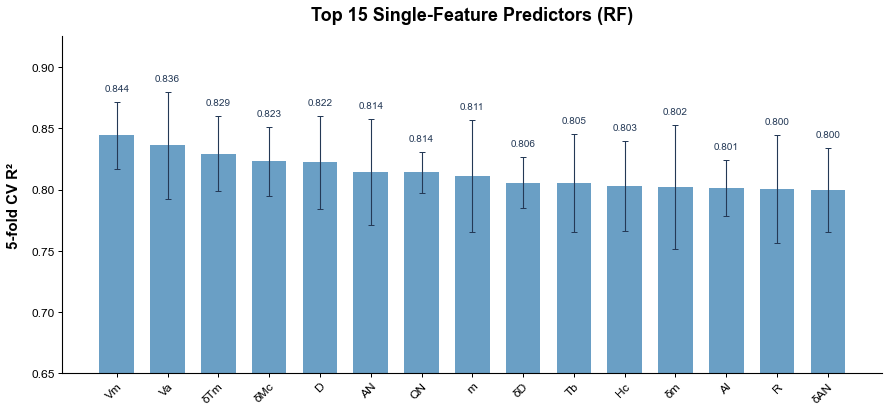


FEATURE IMPORTANCE EVALUATION COMPLETED
Recommended model: RF
Total evaluated features: 72
Top-ranked feature: Vm
Top feature CV R2: 0.8444

Saved files:
1. 04_PCC_Feature_Importance.xlsx
2. 04_PCC_Feature_Importance.png


In [5]:
# ============================================================
# 04. FEATURE ENGINEERING - FEATURE IMPORTANCE
# Single-Feature Predictive Importance Evaluation
#
# Inputs:
#   Chap10_Data.xlsx
#   03_Model_Comparison_Results.xlsx
#
# Outputs:
#   04_PCC_Feature_Importance.xlsx
#   04_PCC_Feature_Importance.png
#
# Description:
#   - Automatically load the recommended ML model
#   - Evaluate each feature independently using 5-fold CV
#   - Rank all features by mean CV R2
#   - Visualize the top 15 individual predictors
#   - Save complete rankings for subsequent PCC screening
# ============================================================


# ------------------------------------------------------------
# 1. Import Libraries
# ------------------------------------------------------------

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import (
    train_test_split,
    KFold,
    cross_validate
)

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

from sklearn.ensemble import (
    GradientBoostingRegressor,
    RandomForestRegressor,
    AdaBoostRegressor
)

from sklearn.tree import DecisionTreeRegressor
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from sklearn.neural_network import MLPRegressor

from xgboost import XGBRegressor


# ------------------------------------------------------------
# 2. General Settings
# ------------------------------------------------------------

INPUT_FILE = "Chap10_Data.xlsx"
MODEL_FILE = "03_Model_Comparison_Results.xlsx"

FIGURE_FILE = "04_PCC_Feature_Importance.png"
EXCEL_FILE = "04_PCC_Feature_Importance.xlsx"

TOP_N = 15
DPI = 600
N_JOBS = -1

# Figure settings
FIG_SIZE = (12.8, 7.2)
YMIN = 0.65

# Colors
BLUE = "#6A9FC5"
DARK_BLUE = "#243956"

plt.rcParams.update({
    "font.family": "Arial",
    "font.size": 13,
    "axes.labelsize": 15,
    "axes.titlesize": 18,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "axes.linewidth": 1.1,
    "xtick.direction": "out",
    "ytick.direction": "out",
    "xtick.major.size": 5,
    "ytick.major.size": 4,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.dpi": DPI
})


# ------------------------------------------------------------
# 3. Load Recommended Model Settings
# ------------------------------------------------------------

# Read the recommended algorithm and experimental settings
# saved by Step 03 - Model Comparison.

model_info = pd.read_excel(
    MODEL_FILE,
    sheet_name="Best_Model"
)

MODEL_NAME = str(
    model_info.loc[0, "Model"]
).strip()

RANDOM_STATE = int(
    model_info.loc[0, "Random_State"]
)

TEST_SIZE = float(
    model_info.loc[0, "Test_Size"]
)

CV_FOLDS = int(
    model_info.loc[0, "CV_Folds"]
)

print("=" * 65)
print("04. SINGLE-FEATURE IMPORTANCE EVALUATION")
print("=" * 65)

print(f"Input file       : {INPUT_FILE}")
print(f"Model settings   : {MODEL_FILE}")
print(f"Recommended model: {MODEL_NAME}")
print(f"Random state     : {RANDOM_STATE}")
print(f"Test size        : {TEST_SIZE}")
print(f"CV folds         : {CV_FOLDS}")

print("=" * 65)


# ------------------------------------------------------------
# 4. Load Dataset
# ------------------------------------------------------------

df = pd.read_excel(INPUT_FILE)

# First column: Vickers hardness (Hv)
# Remaining columns: Input features

target_col = df.columns[0]
feature_cols = list(df.columns[1:])

# Convert target and input features to numerical values
y_all = pd.to_numeric(
    df[target_col],
    errors="coerce"
)

X_all = df[feature_cols].apply(
    pd.to_numeric,
    errors="coerce"
)

# Replace infinite values with NaN
X_all = X_all.replace(
    [np.inf, -np.inf],
    np.nan
)

# Remove samples with missing target values
valid_mask = y_all.notna()

X = X_all.loc[valid_mask].copy()
y = y_all.loc[valid_mask].copy()

if len(X) < 20:
    raise ValueError(
        "Insufficient samples for feature evaluation."
    )


# ------------------------------------------------------------
# 5. Reproduce Train/Test Split
# ------------------------------------------------------------

# Use the same splitting settings as Model Comparison.
# Only training samples are used for feature evaluation.

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE
)

# Remove features containing only missing values
# in the training dataset.

valid_features = X_train.columns[
    X_train.notna().any(axis=0)
].tolist()

if not valid_features:
    raise ValueError(
        "No usable input features were found."
    )

X_train = X_train[valid_features].copy()

# Exclude features with no variation.
# Such features cannot provide predictive information.

valid_features = [
    feature
    for feature in valid_features
    if X_train[feature].nunique(dropna=True) > 1
]

if not valid_features:
    raise ValueError(
        "No variable input features were found."
    )

X_train = X_train[valid_features].copy()

print("\nDataset information:")
print(f"Total samples           : {len(X)}")
print(f"Training samples        : {len(X_train)}")
print(f"Reserved testing samples: {len(X_test)}")
print(f"Candidate features      : {len(valid_features)}")


# ------------------------------------------------------------
# 6. Define Machine Learning Models
# ------------------------------------------------------------

def get_model(model_name):

    if model_name == "GDB":

        return GradientBoostingRegressor(
            random_state=RANDOM_STATE
        )

    elif model_name == "RF":

        return RandomForestRegressor(
            n_estimators=300,
            random_state=RANDOM_STATE,
            n_jobs=1
        )

    elif model_name == "XGB":

        return XGBRegressor(
            n_estimators=300,
            objective="reg:squarederror",
            random_state=RANDOM_STATE,
            n_jobs=1,
            verbosity=0
        )

    elif model_name == "ADB":

        return AdaBoostRegressor(
            n_estimators=100,
            random_state=RANDOM_STATE
        )

    elif model_name == "DT":

        return DecisionTreeRegressor(
            random_state=RANDOM_STATE
        )

    elif model_name == "SVM-lin":

        return SVR(kernel="linear")

    elif model_name == "SVM-poly":

        return SVR(kernel="poly")

    elif model_name == "SVM-rbf":

        return SVR(kernel="rbf")

    elif model_name == "KNN":

        return KNeighborsRegressor(
            n_neighbors=5
        )

    elif model_name == "MLP":

        return MLPRegressor(
            hidden_layer_sizes=(64, 32),
            activation="relu",
            solver="adam",
            max_iter=3000,
            early_stopping=True,
            random_state=RANDOM_STATE
        )

    else:

        raise ValueError(
            f"Unsupported model: {model_name}"
        )


# ------------------------------------------------------------
# 7. Build Preprocessing Pipeline
# ------------------------------------------------------------

# Scaling is required for SVM, KNN, and MLP.
# Tree-based models do not require feature scaling.

SCALE_MODELS = {
    "SVM-lin",
    "SVM-poly",
    "SVM-rbf",
    "KNN",
    "MLP"
}


def build_pipeline(model_name):

    steps = [
        ("imputer", SimpleImputer(strategy="median"))
    ]

    if model_name in SCALE_MODELS:

        steps.append(
            ("scaler", StandardScaler())
        )

    steps.append(
        ("model", get_model(model_name))
    )

    return Pipeline(steps)


# ------------------------------------------------------------
# 8. Cross-Validation Settings
# ------------------------------------------------------------

cv = KFold(
    n_splits=CV_FOLDS,
    shuffle=True,
    random_state=RANDOM_STATE
)

scoring = {
    "R2": "r2"
}


# ------------------------------------------------------------
# 9. Evaluate Individual Feature Importance
# ------------------------------------------------------------

# Each feature is independently used to train the same
# recommended algorithm.
#
# The mean 5-fold CV R2 measures the individual predictive
# performance of that feature.

results = []

for i, feature in enumerate(valid_features, start=1):

    X_single = X_train[[feature]]

    pipeline = build_pipeline(MODEL_NAME)

    cv_results = cross_validate(
        pipeline,
        X_single,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=N_JOBS,
        error_score="raise"
    )

    r2_scores = cv_results["test_R2"]

    mean_r2 = float(np.mean(r2_scores))
    std_r2 = float(np.std(r2_scores, ddof=1))

    results.append({
        "Feature": feature,
        "CV_R2_Mean": mean_r2,
        "CV_R2_STD": std_r2
    })

    print(
        f"[{i:02d}/{len(valid_features)}] "
        f"{feature}: CV R2 = {mean_r2:.4f}"
    )


# ------------------------------------------------------------
# 10. Rank All Features
# ------------------------------------------------------------

importance_df = pd.DataFrame(results)

# Rank features by mean CV R2
importance_df = importance_df.sort_values(
    by="CV_R2_Mean",
    ascending=False,
    kind="stable"
).reset_index(drop=True)

importance_df.insert(
    0,
    "Rank",
    np.arange(1, len(importance_df) + 1)
)

# Record the model used for evaluation
importance_df["Model"] = MODEL_NAME

# Extract the top-ranked features
top_df = importance_df.head(TOP_N).copy()

print("\n" + "=" * 65)
print(f"TOP {len(top_df)} SINGLE-FEATURE PREDICTORS")
print("=" * 65)

print(
    top_df.round(4).to_string(index=False)
)


# ------------------------------------------------------------
# 11. Save Feature Importance Results
# ------------------------------------------------------------

settings_df = pd.DataFrame([{
    "Model": MODEL_NAME,
    "Selection_Source": MODEL_FILE,
    "Ranking_Metric": "Mean 5-fold CV R2",
    "Random_State": RANDOM_STATE,
    "Test_Size": TEST_SIZE,
    "CV_Folds": CV_FOLDS,
    "Number_of_Features": len(valid_features)
}])

with pd.ExcelWriter(
    EXCEL_FILE,
    engine="openpyxl"
) as writer:

    # Complete ranking used in subsequent PCC screening
    importance_df.to_excel(
        writer,
        sheet_name="All_Feature_Ranking",
        index=False
    )

    # Top-ranked features used for visualization
    top_df.to_excel(
        writer,
        sheet_name="Top15_Features",
        index=False
    )

    # Model and evaluation settings
    settings_df.to_excel(
        writer,
        sheet_name="Settings",
        index=False
    )

    # Format Excel worksheets
    for sheet in writer.sheets.values():

        sheet.freeze_panes = "B2"
        sheet.auto_filter.ref = sheet.dimensions

        for column_cells in sheet.columns:

            max_length = max(
                len(str(cell.value))
                if cell.value is not None else 0
                for cell in column_cells
            )

            column_letter = column_cells[0].column_letter

            sheet.column_dimensions[
                column_letter
            ].width = min(max_length + 3, 42)

print(f"\nExcel results saved: {EXCEL_FILE}")


# ------------------------------------------------------------
# 12. Prepare Top 15 Visualization
# ------------------------------------------------------------

plot_df = top_df.copy()

x = np.arange(len(plot_df))

values = plot_df[
    "CV_R2_Mean"
].to_numpy(dtype=float)

errors = plot_df[
    "CV_R2_STD"
].to_numpy(dtype=float)

labels = plot_df["Feature"].tolist()

fig, ax = plt.subplots(
    figsize=FIG_SIZE,
    facecolor="white"
)


# ------------------------------------------------------------
# 13. Plot Feature Performance
# ------------------------------------------------------------

# 13.1 Performance bars
ax.bar(
    x,
    values,
    width=0.68,
    color=BLUE,
    edgecolor="none",
    zorder=2
)

# 13.2 CV standard deviation error bars
ax.errorbar(
    x,
    values,
    yerr=errors,
    fmt="none",
    ecolor=DARK_BLUE,
    elinewidth=1.1,
    capsize=2.8,
    capthick=1.0,
    zorder=3
)

# 13.3 Display mean CV R2 values
for xi, value, error in zip(x, values, errors):

    ax.text(
        xi,
        value + error + 0.007,
        f"{value:.3f}",
        ha="center",
        va="bottom",
        fontsize=10,
        color=DARK_BLUE
    )


# ------------------------------------------------------------
# 14. Figure Formatting
# ------------------------------------------------------------

ax.set_title(
    f"Top {len(plot_df)} Single-Feature Predictors ({MODEL_NAME})",
    fontsize=18,
    fontweight="bold",
    pad=16
)

ax.set_ylabel(
    "5-fold CV R²",
    fontsize=15,
    fontweight="bold",
    labelpad=10
)

ax.set_xticks(x)

ax.set_xticklabels(
    labels,
    rotation=45,
    ha="right",
    rotation_mode="anchor"
)

# Y-axis limits
y_max = float(
    np.max(values + errors)
) + 0.045

# Extend the lower limit if some features have lower R2.
plot_ymin = min(
    YMIN,
    float(np.min(values - errors)) - 0.02
)

ax.set_ylim(
    plot_ymin,
    y_max
)

# Axis formatting
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.spines["left"].set_linewidth(1.1)
ax.spines["bottom"].set_linewidth(1.1)

ax.tick_params(
    axis="both",
    direction="out",
    length=4,
    width=1.0
)

ax.grid(False)

# Figure layout
fig.subplots_adjust(
    left=0.09,
    right=0.98,
    bottom=0.23,
    top=0.88
)


# ------------------------------------------------------------
# 15. Save and Display
# ------------------------------------------------------------

fig.savefig(
    FIGURE_FILE,
    dpi=DPI,
    facecolor="white",
    bbox_inches="tight",
    pad_inches=0.03
)

plt.show()
plt.close(fig)


# ------------------------------------------------------------
# 16. Final Summary
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("FEATURE IMPORTANCE EVALUATION COMPLETED")
print("=" * 65)

print(f"Recommended model: {MODEL_NAME}")
print(f"Total evaluated features: {len(importance_df)}")

print(
    f"Top-ranked feature: "
    f"{importance_df.loc[0, 'Feature']}"
)

print(
    f"Top feature CV R2: "
    f"{importance_df.loc[0, 'CV_R2_Mean']:.4f}"
)

print("\nSaved files:")
print(f"1. {EXCEL_FILE}")
print(f"2. {FIGURE_FILE}")

print("=" * 65)

04. IMPORTANCE-GUIDED PCC SCREENING
PCC matrix file       : 04_PCC_Correlation_Matrix.xlsx
Feature ranking file  : 04_PCC_Feature_Importance.xlsx
Original features     : 72
Screening threshold   : 0.95

PCC SCREENING RESULTS
Original features : 72
Retained features : 33
Removed features  : 39
Retention rate    : 45.8%
Reduction rate    : 54.2%

Retained features:
01. Vm
02. δQN
03. χP
04. δHf
05. Ev
06. δEa
07. Tm
08. EI-3rd
09. δDVE
10. δχP
11. Ew
12. Ni
13. δC
14. δRc
15. ΔHmix
16. δEI-2nd
17. δEw
18. Rc
19. Fe
20. DCE
21. Cu
22. δe/a
23. δΔHmix
24. EN
25. χM
26. δEN
27. Co
28. δEI-3rd
29. DVE
30. δDCE
31. EI-2nd
32. Cr
33. δHs


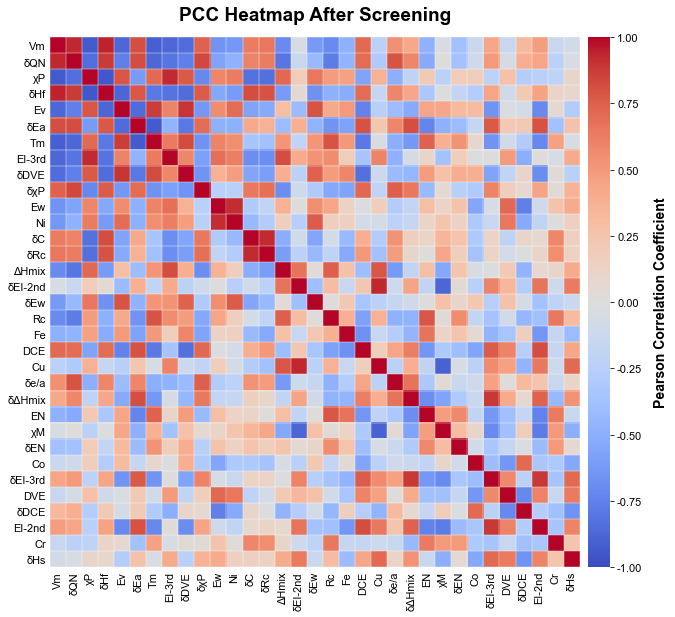


IMPORTANCE-GUIDED PCC SCREENING COMPLETED
Original features: 72
Retained features: 33
Removed features : 39
Reduction rate   : 54.2%

Saved files:
1. 04_PCC_Selected_Features.xlsx
2. 04_PCC_Selected_Heatmap.png


In [6]:
# ============================================================
# 04. FEATURE ENGINEERING - PCC FEATURE SCREENING
# Importance-Guided Pearson Correlation Screening
#
# Inputs:
#   04_PCC_Correlation_Matrix.xlsx
#   04_PCC_Feature_Importance.xlsx
#
# Outputs:
#   04_PCC_Selected_Features.xlsx
#   04_PCC_Selected_Heatmap.png
#
# Description:
#   - Rank features by single-feature CV R2
#   - Identify redundant features using PCC
#   - Retain higher-ranked features
#   - Remove lower-ranked features with |PCC| > 0.95
#   - Visualize the PCC matrix after screening
# ============================================================


# ------------------------------------------------------------
# 1. Import Libraries
# ------------------------------------------------------------

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from matplotlib.colors import TwoSlopeNorm
from matplotlib.ticker import FormatStrFormatter
from mpl_toolkits.axes_grid1 import make_axes_locatable


# ------------------------------------------------------------
# 2. General Settings
# ------------------------------------------------------------

PCC_FILE = "04_PCC_Correlation_Matrix.xlsx"
IMPORTANCE_FILE = "04_PCC_Feature_Importance.xlsx"

EXCEL_FILE = "04_PCC_Selected_Features.xlsx"
FIGURE_FILE = "04_PCC_Selected_Heatmap.png"

PCC_THRESHOLD = 0.95
DPI = 600

# Heatmap settings
FIG_SIZE = (11.2, 9.2)
LABEL_STEP = 1

# Display every feature label when LABEL_STEP = 1.

plt.rcParams.update({
    "font.family": "Arial",
    "font.size": 12,
    "axes.labelsize": 14,
    "axes.titlesize": 17,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "axes.linewidth": 1.0,
    "xtick.direction": "out",
    "ytick.direction": "out",
    "xtick.major.size": 5,
    "ytick.major.size": 4,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.dpi": DPI
})


# ------------------------------------------------------------
# 3. Load Feature Importance Rankings
# ------------------------------------------------------------

importance_df = pd.read_excel(
    IMPORTANCE_FILE,
    sheet_name="All_Feature_Ranking"
)

# Check required columns
required_columns = ["Feature", "CV_R2_Mean"]

if not all(
    col in importance_df.columns
    for col in required_columns
):
    raise ValueError(
        "Feature importance results must contain "
        "'Feature' and 'CV_R2_Mean'."
    )

importance_df["Feature"] = (
    importance_df["Feature"].astype(str)
)

# Sort by individual predictive performance
importance_df = importance_df.sort_values(
    by="CV_R2_Mean",
    ascending=False,
    kind="stable"
).reset_index(drop=True)

# Update feature ranking
importance_df["Rank"] = np.arange(
    1,
    len(importance_df) + 1
)

ranked_features = importance_df["Feature"].tolist()

# Check for duplicate feature names
if len(ranked_features) != len(set(ranked_features)):
    raise ValueError(
        "Duplicate feature names found in importance results."
    )

if not ranked_features:
    raise ValueError(
        "No ranked features found."
    )


# ------------------------------------------------------------
# 4. Load PCC Matrix
# ------------------------------------------------------------

pcc_matrix = pd.read_excel(
    PCC_FILE,
    sheet_name="PCC_Matrix",
    index_col=0
)

pcc_matrix.index = pcc_matrix.index.astype(str)
pcc_matrix.columns = pcc_matrix.columns.astype(str)

# Check consistency between the two input files
missing_features = [
    feature for feature in ranked_features
    if (
        feature not in pcc_matrix.index
        or feature not in pcc_matrix.columns
    )
]

if missing_features:
    raise ValueError(
        "Features missing from the PCC matrix: "
        f"{missing_features}"
    )

# Reorder matrix according to feature importance
pcc_matrix = pcc_matrix.loc[
    ranked_features,
    ranked_features
].apply(
    pd.to_numeric,
    errors="coerce"
)

# Validate correlation values
matrix_values = pcc_matrix.to_numpy(dtype=float)

if not np.isfinite(matrix_values).all():
    raise ValueError(
        "PCC matrix contains missing or invalid values."
    )

if np.any(np.abs(matrix_values) > 1.000001):
    raise ValueError(
        "PCC values must be within [-1, 1]."
    )

print("=" * 65)
print("04. IMPORTANCE-GUIDED PCC SCREENING")
print("=" * 65)

print(f"PCC matrix file       : {PCC_FILE}")
print(f"Feature ranking file  : {IMPORTANCE_FILE}")
print(f"Original features     : {len(ranked_features)}")
print(f"Screening threshold   : {PCC_THRESHOLD}")

print("=" * 65)


# ------------------------------------------------------------
# 5. Importance-Guided PCC Screening
# ------------------------------------------------------------

# Screening strategy:
# 1. Start from the highest-ranked feature.
# 2. Retain the current available feature.
# 3. Remove lower-ranked features if |PCC| > threshold.
# 4. Repeat until all features are processed.

selected_features = []
removed_features = set()
screening_records = []

# Feature importance lookup table
importance_lookup = importance_df.set_index("Feature")

for i, feature in enumerate(ranked_features):

    # Skip features already removed
    if feature in removed_features:
        continue

    # Retain the highest-ranked available feature
    selected_features.append(feature)

    current_rank = int(
        importance_lookup.loc[feature, "Rank"]
    )

    current_r2 = float(
        importance_lookup.loc[feature, "CV_R2_Mean"]
    )

    # Compare with lower-ranked features
    for other_feature in ranked_features[i + 1:]:

        if other_feature in removed_features:
            continue

        pcc_value = float(
            pcc_matrix.loc[feature, other_feature]
        )

        # Remove highly correlated lower-ranked features
        if abs(pcc_value) > PCC_THRESHOLD:

            removed_features.add(other_feature)

            screening_records.append({
                "Retained_Feature": feature,
                "Retained_Rank": current_rank,
                "Retained_CV_R2": current_r2,

                "Removed_Feature": other_feature,
                "Removed_Rank": int(
                    importance_lookup.loc[
                        other_feature, "Rank"
                    ]
                ),
                "Removed_CV_R2": float(
                    importance_lookup.loc[
                        other_feature, "CV_R2_Mean"
                    ]
                ),

                "PCC": pcc_value,
                "Absolute_PCC": abs(pcc_value)
            })


# ------------------------------------------------------------
# 6. Organize Screening Results
# ------------------------------------------------------------

selected_set = set(selected_features)

# Complete feature ranking with screening status
screened_df = importance_df.copy()

screened_df["Status"] = screened_df["Feature"].apply(
    lambda feature: (
        "Retained"
        if feature in selected_set
        else "Removed"
    )
)

# Retained features
selected_df = screened_df[
    screened_df["Status"] == "Retained"
].copy().reset_index(drop=True)

selected_df.insert(
    0,
    "Selected_Rank",
    np.arange(1, len(selected_df) + 1)
)

# Removed features
removed_df = screened_df[
    screened_df["Status"] == "Removed"
].copy().reset_index(drop=True)

# Complete screening records
screening_log_df = pd.DataFrame(
    screening_records,
    columns=[
        "Retained_Feature",
        "Retained_Rank",
        "Retained_CV_R2",
        "Removed_Feature",
        "Removed_Rank",
        "Removed_CV_R2",
        "PCC",
        "Absolute_PCC"
    ]
)

# Add removal reasons to removed feature records
if not screening_log_df.empty:

    removal_info = screening_log_df[
        [
            "Removed_Feature",
            "Retained_Feature",
            "PCC",
            "Absolute_PCC"
        ]
    ]

    removed_df = removed_df.merge(
        removal_info,
        left_on="Feature",
        right_on="Removed_Feature",
        how="left"
    ).drop(
        columns=["Removed_Feature"]
    )


# ------------------------------------------------------------
# 7. Screening Statistics
# ------------------------------------------------------------

n_original = len(ranked_features)
n_selected = len(selected_features)
n_removed = len(removed_features)

retention_rate = 100 * n_selected / n_original
reduction_rate = 100 * n_removed / n_original

# Validate screening results
assert n_selected + n_removed == n_original
assert selected_set.isdisjoint(removed_features)

print("\n" + "=" * 65)
print("PCC SCREENING RESULTS")
print("=" * 65)

print(f"Original features : {n_original}")
print(f"Retained features : {n_selected}")
print(f"Removed features  : {n_removed}")
print(f"Retention rate    : {retention_rate:.1f}%")
print(f"Reduction rate    : {reduction_rate:.1f}%")

print("\nRetained features:")

for i, feature in enumerate(selected_features, start=1):
    print(f"{i:02d}. {feature}")


# ------------------------------------------------------------
# 8. Calculate PCC Matrix After Screening
# ------------------------------------------------------------

selected_pcc = pcc_matrix.loc[
    selected_features,
    selected_features
].copy()

# Verify that all retained pairs satisfy the threshold
if n_selected > 1:

    absolute_corr = selected_pcc.abs().to_numpy()

    upper_values = absolute_corr[
        np.triu_indices(n_selected, k=1)
    ]

    if np.any(upper_values > PCC_THRESHOLD):
        raise ValueError(
            "Highly correlated features remain after screening."
        )


# ------------------------------------------------------------
# 9. Save Screening Results to Excel
# ------------------------------------------------------------

# Summary information
summary_df = pd.DataFrame([{
    "Original_Features": n_original,
    "Retained_Features": n_selected,
    "Removed_Features": n_removed,
    "Retention_Rate_%": retention_rate,
    "Reduction_Rate_%": reduction_rate,
    "PCC_Threshold": PCC_THRESHOLD,
    "Screening_Method": "Importance-Guided PCC Screening"
}])

# Simple feature list for subsequent RFE
selected_list_df = pd.DataFrame({
    "Feature": selected_features
})

with pd.ExcelWriter(
    EXCEL_FILE,
    engine="openpyxl"
) as writer:

    # Screening statistics
    summary_df.to_excel(
        writer,
        sheet_name="Summary",
        index=False
    )

    # Retained features with importance scores
    selected_df.to_excel(
        writer,
        sheet_name="Selected_Features",
        index=False
    )

    # Simple feature list for RFE
    selected_list_df.to_excel(
        writer,
        sheet_name="Selected_Feature_List",
        index=False
    )

    # Removed features with reasons
    removed_df.to_excel(
        writer,
        sheet_name="Removed_Features",
        index=False
    )

    # Complete removal records
    screening_log_df.to_excel(
        writer,
        sheet_name="Screening_Log",
        index=False
    )

    # All original features and their status
    screened_df.to_excel(
        writer,
        sheet_name="All_Features",
        index=False
    )

    # Correlation matrix of retained features
    selected_pcc.to_excel(
        writer,
        sheet_name="Selected_PCC_Matrix",
        index_label="Feature"
    )

    # Format Excel worksheets
    for sheet in writer.sheets.values():

        sheet.freeze_panes = "B2"
        sheet.auto_filter.ref = sheet.dimensions

        for column_cells in sheet.columns:

            max_length = max(
                len(str(cell.value))
                if cell.value is not None else 0
                for cell in column_cells
            )

            column_letter = column_cells[0].column_letter

            sheet.column_dimensions[
                column_letter
            ].width = min(max_length + 3, 40)


# ------------------------------------------------------------
# 10. Create PCC Heatmap After Screening
# ------------------------------------------------------------

# Automatically adjust feature label size
if n_selected <= 35:
    label_size = 11
elif n_selected <= 50:
    label_size = 9
else:
    label_size = 8

fig, ax = plt.subplots(
    figsize=FIG_SIZE,
    facecolor="white"
)

# Color map
cmap = plt.get_cmap("coolwarm").copy()
cmap.set_bad("white")

norm = TwoSlopeNorm(
    vmin=-1,
    vcenter=0,
    vmax=1
)

# Full PCC heatmap
im = ax.imshow(
    selected_pcc.to_numpy(),
    cmap=cmap,
    norm=norm,
    origin="upper",
    interpolation="nearest",
    aspect="equal"
)


# ------------------------------------------------------------
# 11. Heatmap Feature Labels
# ------------------------------------------------------------

feature_names = selected_pcc.columns.tolist()
n_features = len(feature_names)

label_positions = np.arange(
    0,
    n_features,
    LABEL_STEP
)

ax.set_xticks(label_positions)
ax.set_yticks(label_positions)

ax.set_xticklabels(
    [feature_names[i] for i in label_positions],
    rotation=90,
    ha="center",
    va="top",
    fontsize=label_size
)

ax.set_yticklabels(
    [feature_names[i] for i in label_positions],
    fontsize=label_size
)

ax.tick_params(
    axis="both",
    which="major",
    length=0,
    pad=4
)


# ------------------------------------------------------------
# 12. White Cell Boundaries
# ------------------------------------------------------------

ax.set_xticks(
    np.arange(-0.5, n_features, 1),
    minor=True
)

ax.set_yticks(
    np.arange(-0.5, n_features, 1),
    minor=True
)

ax.grid(
    which="minor",
    color="white",
    linewidth=0.45,
    alpha=0.9
)

ax.tick_params(
    which="minor",
    bottom=False,
    top=False,
    left=False,
    right=False
)

# Remove outer frame
for spine in ax.spines.values():
    spine.set_visible(False)


# ------------------------------------------------------------
# 13. Colorbar
# ------------------------------------------------------------

# Attach the colorbar to the heatmap.
# The colorbar height matches the heatmap height.

divider = make_axes_locatable(ax)

cax = divider.append_axes(
    "right",
    size="4%",
    pad=0.12
)

cbar = fig.colorbar(
    im,
    cax=cax,
    orientation="vertical"
)

cbar.set_label(
    "Pearson Correlation Coefficient",
    fontsize=14,
    fontweight="bold",
    labelpad=12
)

cbar.set_ticks([
    -1.00,
    -0.75,
    -0.50,
    -0.25,
    0.00,
    0.25,
    0.50,
    0.75,
    1.00
])

cbar.ax.yaxis.set_major_formatter(
    FormatStrFormatter("%.2f")
)

cbar.ax.tick_params(
    labelsize=11,
    length=4,
    width=0.8
)

cbar.outline.set_visible(False)


# ------------------------------------------------------------
# 14. Figure Title and Layout
# ------------------------------------------------------------

ax.set_title(
    "PCC Heatmap After Screening",
    fontsize=19,
    fontweight="bold",
    pad=17
)

fig.subplots_adjust(
    left=0.12,
    right=0.89,
    bottom=0.10,
    top=0.90
)


# ------------------------------------------------------------
# 15. Save and Display
# ------------------------------------------------------------

fig.savefig(
    FIGURE_FILE,
    dpi=DPI,
    facecolor="white",
    bbox_inches="tight",
    pad_inches=0.03
)

plt.show()
plt.close(fig)


# ------------------------------------------------------------
# 16. Final Summary
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("IMPORTANCE-GUIDED PCC SCREENING COMPLETED")
print("=" * 65)

print(f"Original features: {n_original}")
print(f"Retained features: {n_selected}")
print(f"Removed features : {n_removed}")
print(f"Reduction rate   : {reduction_rate:.1f}%")

print("\nSaved files:")
print(f"1. {EXCEL_FILE}")
print(f"2. {FIGURE_FILE}")

print("=" * 65)

05. RECURSIVE FEATURE ELIMINATION
Recommended model : RF
Random state      : 42
Test size         : 0.2
CV folds          : 5
R2 tolerance      : 0.01

PCC-selected features:
Number of features: 33
['Vm', 'δQN', 'χP', 'δHf', 'Ev', 'δEa', 'Tm', 'EI-3rd', 'δDVE', 'δχP', 'Ew', 'Ni', 'δC', 'δRc', 'ΔHmix', 'δEI-2nd', 'δEw', 'Rc', 'Fe', 'DCE', 'Cu', 'δe/a', 'δΔHmix', 'EN', 'χM', 'δEN', 'Co', 'δEI-3rd', 'DVE', 'δDCE', 'EI-2nd', 'Cr', 'δHs']

Dataset information:
Training samples : 240
Testing samples  : 60
Initial features : 33

Running RFECV ...

PERFORMANCE-TOLERANCE SELECTION
Maximum CV R2             : 0.9102
Feature count at maximum  : 33
R2 tolerance              : 0.0100
Minimum acceptable CV R2  : 0.9002
Selected feature count    : 4
Selected CV R2            : 0.9032

Final selected features:
['Vm', 'δQN', 'χP', 'δHf']


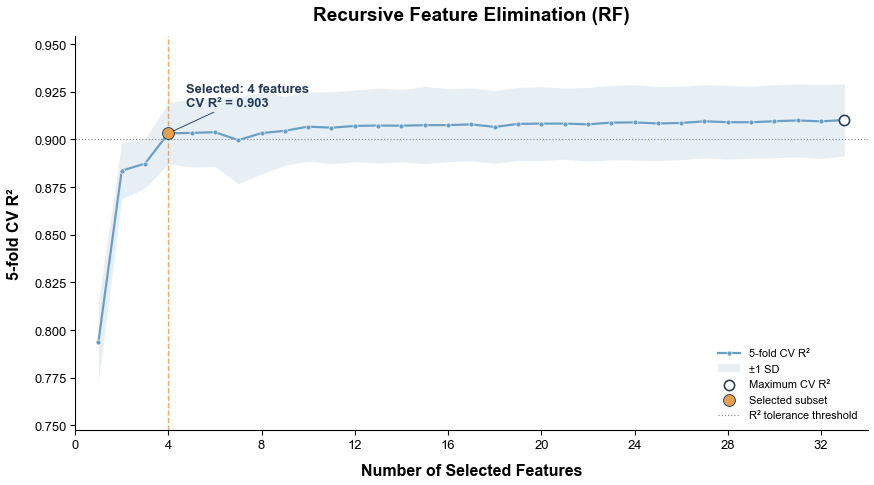


RECURSIVE FEATURE ELIMINATION COMPLETED
Recommended model    : RF
Initial features     : 33
Maximum CV R2        : 0.9102
R2 tolerance         : 0.0100
Selected feature count: 4
Selected CV R2       : 0.9032

Selected features:
['Vm', 'δQN', 'χP', 'δHf']

Saved files:
1. 05_RFE_Results.xlsx
2. 05_RFE_Performance.png


In [7]:
# ============================================================
# 05. FEATURE ENGINEERING - RECURSIVE FEATURE ELIMINATION
# Performance-Tolerance Recursive Feature Elimination (RFE)
#
# Inputs:
#   Chap10_Data.xlsx
#   03_Model_Comparison_Results.xlsx
#   04_PCC_Selected_Features.xlsx
#
# Outputs:
#   05_RFE_Results.xlsx
#   05_RFE_Performance.png
#
# Description:
#   - Automatically load the recommended ML model
#   - Use features retained after PCC screening
#   - Evaluate feature subsets using 5-fold RFECV
#   - Select the smallest subset within the R2 tolerance
#   - Refit RFE to identify the final selected features
# ============================================================


# ------------------------------------------------------------
# 1. Import Libraries
# ------------------------------------------------------------

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from matplotlib.ticker import MaxNLocator

from sklearn.model_selection import train_test_split, KFold
from sklearn.feature_selection import RFE, RFECV
from sklearn.base import clone

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

from sklearn.ensemble import (
    GradientBoostingRegressor,
    RandomForestRegressor,
    AdaBoostRegressor
)

from sklearn.tree import DecisionTreeRegressor
from sklearn.svm import SVR
from xgboost import XGBRegressor


# ------------------------------------------------------------
# 2. General Settings
# ------------------------------------------------------------

INPUT_FILE = "Chap10_Data.xlsx"
MODEL_FILE = "03_Model_Comparison_Results.xlsx"
PCC_FILE = "04_PCC_Selected_Features.xlsx"

EXCEL_FILE = "05_RFE_Results.xlsx"
FIGURE_FILE = "05_RFE_Performance.png"

# Feature selection settings
R2_TOLERANCE = 0.01
RFE_STEP = 1
MIN_FEATURES = 1

N_JOBS = -1
DPI = 600

# Figure settings
FIG_SIZE = (12.8, 7.2)

# Colors
BLUE = "#6A9FC5"
ORANGE = "#E6A04B"
DARK_BLUE = "#243956"
GRAY = "#777777"

plt.rcParams.update({
    "font.family": "Arial",
    "font.size": 13,
    "axes.labelsize": 16,
    "axes.titlesize": 18,
    "xtick.labelsize": 13,
    "ytick.labelsize": 13,
    "axes.linewidth": 1.1,
    "xtick.direction": "out",
    "ytick.direction": "out",
    "xtick.major.size": 5,
    "ytick.major.size": 5,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.dpi": DPI
})


# ------------------------------------------------------------
# 3. Load Recommended Model Settings
# ------------------------------------------------------------

model_info = pd.read_excel(
    MODEL_FILE,
    sheet_name="Best_Model"
)

MODEL_NAME = str(
    model_info.loc[0, "Model"]
).strip()

RANDOM_STATE = int(
    model_info.loc[0, "Random_State"]
)

TEST_SIZE = float(
    model_info.loc[0, "Test_Size"]
)

CV_FOLDS = int(
    model_info.loc[0, "CV_Folds"]
)

print("=" * 65)
print("05. RECURSIVE FEATURE ELIMINATION")
print("=" * 65)

print(f"Recommended model : {MODEL_NAME}")
print(f"Random state      : {RANDOM_STATE}")
print(f"Test size         : {TEST_SIZE}")
print(f"CV folds          : {CV_FOLDS}")
print(f"R2 tolerance      : {R2_TOLERANCE}")

print("=" * 65)


# ------------------------------------------------------------
# 4. Load PCC-Selected Features
# ------------------------------------------------------------

selected_feature_df = pd.read_excel(
    PCC_FILE,
    sheet_name="Selected_Feature_List"
)

pcc_features = (
    selected_feature_df["Feature"]
    .dropna()
    .astype(str)
    .tolist()
)

if len(pcc_features) < MIN_FEATURES:
    raise ValueError(
        "Insufficient PCC-selected features."
    )

if len(pcc_features) != len(set(pcc_features)):
    raise ValueError(
        "Duplicate feature names detected."
    )

print("\nPCC-selected features:")
print(f"Number of features: {len(pcc_features)}")
print(pcc_features)


# ------------------------------------------------------------
# 5. Load Dataset
# ------------------------------------------------------------

df = pd.read_excel(INPUT_FILE)

# First column: Vickers hardness (Hv)
# Remaining columns: Input features

target_col = df.columns[0]
feature_cols = list(df.columns[1:])

# Check whether selected features exist in dataset
missing_features = [
    feature for feature in pcc_features
    if feature not in feature_cols
]

if missing_features:
    raise ValueError(
        f"Features missing from dataset: {missing_features}"
    )

# Convert data to numerical values
y_all = pd.to_numeric(
    df[target_col],
    errors="coerce"
)

X_all = df[feature_cols].apply(
    pd.to_numeric,
    errors="coerce"
)

X_all = X_all.replace(
    [np.inf, -np.inf],
    np.nan
)

# Remove samples with missing target values
valid_mask = y_all.notna()

X = X_all.loc[valid_mask].copy()
y = y_all.loc[valid_mask].copy()


# ------------------------------------------------------------
# 6. Reproduce Train/Test Split
# ------------------------------------------------------------

# Use the same splitting settings as Model Comparison.
# The independent test set is excluded from RFE.

X_train_all, X_test_all, y_train, y_test = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE
)

# Keep only PCC-selected features
X_train = X_train_all[pcc_features].copy()
X_test = X_test_all[pcc_features].copy()

if len(X_train) < CV_FOLDS * 2:
    raise ValueError(
        "Insufficient training samples for RFECV."
    )

print("\nDataset information:")
print(f"Training samples : {len(X_train)}")
print(f"Testing samples  : {len(X_test)}")
print(f"Initial features : {X_train.shape[1]}")


# ------------------------------------------------------------
# 7. Define Machine Learning Models
# ------------------------------------------------------------

# Standard RFE requires an estimator that exposes
# feature_importances_ or coef_.
#
# The following models are supported:
# RF, GDB, XGB, ADB, DT, and linear SVM.


def get_model(model_name):

    if model_name == "RF":

        return RandomForestRegressor(
            n_estimators=300,
            random_state=RANDOM_STATE,
            n_jobs=1
        )

    elif model_name == "GDB":

        return GradientBoostingRegressor(
            random_state=RANDOM_STATE
        )

    elif model_name == "XGB":

        return XGBRegressor(
            n_estimators=300,
            objective="reg:squarederror",
            random_state=RANDOM_STATE,
            n_jobs=1,
            verbosity=0
        )

    elif model_name == "ADB":

        return AdaBoostRegressor(
            n_estimators=100,
            random_state=RANDOM_STATE
        )

    elif model_name == "DT":

        return DecisionTreeRegressor(
            random_state=RANDOM_STATE
        )

    elif model_name == "SVM-lin":

        return SVR(
            kernel="linear"
        )

    else:

        raise ValueError(
            f"Model '{model_name}' does not support "
            "standard coefficient/feature-importance RFE."
        )


# ------------------------------------------------------------
# 8. Build Estimator Pipeline
# ------------------------------------------------------------

steps = [
    ("imputer", SimpleImputer(strategy="median"))
]

# Standardization for linear SVM
if MODEL_NAME == "SVM-lin":
    steps.append(
        ("scaler", StandardScaler())
    )

steps.append(
    ("model", get_model(MODEL_NAME))
)

estimator = Pipeline(steps)

# Identify the appropriate feature-importance attribute
if MODEL_NAME == "SVM-lin":
    IMPORTANCE_GETTER = "named_steps.model.coef_"
else:
    IMPORTANCE_GETTER = (
        "named_steps.model.feature_importances_"
    )


# ------------------------------------------------------------
# 9. Validate Missing Values
# ------------------------------------------------------------

# RFECV validates its input before fitting the estimator.
# This workflow requires complete training features.
#
# Stop if missing values are detected to avoid
# preprocessing outside the cross-validation folds.

if X_train.isna().any().any():

    missing_counts = X_train.isna().sum()
    missing_counts = missing_counts[
        missing_counts > 0
    ]

    raise ValueError(
        "Missing values found in RFE input features:\n"
        f"{missing_counts}\n"
        "Please resolve missing values using a "
        "fold-aware preprocessing strategy."
    )


# ------------------------------------------------------------
# 10. RFECV Performance Evaluation
# ------------------------------------------------------------

cv = KFold(
    n_splits=CV_FOLDS,
    shuffle=True,
    random_state=RANDOM_STATE
)

selector = RFECV(
    estimator=clone(estimator),
    step=RFE_STEP,
    min_features_to_select=MIN_FEATURES,
    cv=cv,
    scoring="r2",
    importance_getter=IMPORTANCE_GETTER,
    n_jobs=N_JOBS
)

print("\nRunning RFECV ...")

selector.fit(
    X_train,
    y_train
)

cv_results = selector.cv_results_

cv_mean = np.asarray(
    cv_results["mean_test_score"],
    dtype=float
)

cv_std = np.asarray(
    cv_results["std_test_score"],
    dtype=float
)

# Retrieve the evaluated feature counts
if "n_features" in cv_results:

    feature_counts = np.asarray(
        cv_results["n_features"],
        dtype=int
    )

else:

    # With RFE_STEP = 1, every feature count is evaluated.
    if RFE_STEP != 1:
        raise ValueError(
            "Feature-count reconstruction requires step=1."
        )

    feature_counts = np.arange(
        MIN_FEATURES,
        len(pcc_features) + 1
    )

if len(feature_counts) != len(cv_mean):
    raise ValueError(
        "RFECV result dimensions do not match."
    )

# Organize cross-validation performance
rfe_performance = pd.DataFrame({
    "Number_of_Features": feature_counts,
    "CV_R2_Mean": cv_mean,
    "CV_R2_STD": cv_std
})

rfe_performance = rfe_performance.sort_values(
    by="Number_of_Features"
).reset_index(drop=True)


# ------------------------------------------------------------
# 11. Performance-Tolerance Feature Selection
# ------------------------------------------------------------

# Find the maximum mean CV R2
max_idx = rfe_performance[
    "CV_R2_Mean"
].idxmax()

max_cv_r2 = float(
    rfe_performance.loc[
        max_idx, "CV_R2_Mean"
    ]
)

max_cv_features = int(
    rfe_performance.loc[
        max_idx, "Number_of_Features"
    ]
)

# Define the acceptable performance threshold
r2_threshold = max_cv_r2 - R2_TOLERANCE

# Identify all feature counts within the tolerance
candidate_df = rfe_performance[
    rfe_performance["CV_R2_Mean"] >= r2_threshold
].copy()

# Select the smallest acceptable feature count
optimal_n_features = int(
    candidate_df["Number_of_Features"].min()
)

# Retrieve CV R2 at the selected feature count
optimal_row = rfe_performance[
    rfe_performance["Number_of_Features"]
    == optimal_n_features
].iloc[0]

optimal_cv_r2 = float(
    optimal_row["CV_R2_Mean"]
)

print("\n" + "=" * 65)
print("PERFORMANCE-TOLERANCE SELECTION")
print("=" * 65)

print(f"Maximum CV R2             : {max_cv_r2:.4f}")
print(f"Feature count at maximum  : {max_cv_features}")
print(f"R2 tolerance              : {R2_TOLERANCE:.4f}")
print(f"Minimum acceptable CV R2  : {r2_threshold:.4f}")
print(f"Selected feature count    : {optimal_n_features}")
print(f"Selected CV R2            : {optimal_cv_r2:.4f}")


# ------------------------------------------------------------
# 12. Refit RFE with Selected Feature Count
# ------------------------------------------------------------

# RFECV selects the subset with the maximum CV score.
# Here, the tolerance rule may select a smaller subset.
#
# Therefore, refit RFE using the selected feature count.

final_rfe = RFE(
    estimator=clone(estimator),
    n_features_to_select=optimal_n_features,
    step=RFE_STEP,
    importance_getter=IMPORTANCE_GETTER
)

final_rfe.fit(
    X_train,
    y_train
)

# Retrieve selected feature names
optimal_features = X_train.columns[
    final_rfe.support_
].tolist()

# Retrieve feature elimination ranks
feature_ranking = final_rfe.ranking_

if len(optimal_features) != optimal_n_features:
    raise ValueError(
        "Selected feature count does not match RFE output."
    )

print("\nFinal selected features:")
print(optimal_features)


# ------------------------------------------------------------
# 13. Organize RFE Results
# ------------------------------------------------------------

# Feature elimination ranking
feature_ranking_df = pd.DataFrame({
    "Feature": X_train.columns.tolist(),
    "RFE_Rank": feature_ranking,
    "Selected": final_rfe.support_
})

feature_ranking_df = feature_ranking_df.sort_values(
    by=["RFE_Rank", "Feature"]
).reset_index(drop=True)

# Simple feature list for subsequent BSS
selected_features_df = pd.DataFrame({
    "Feature": optimal_features
})

# Add selection status to CV performance
rfe_performance["Within_Tolerance"] = (
    rfe_performance["CV_R2_Mean"] >= r2_threshold
)

rfe_performance["Selected_Subset"] = (
    rfe_performance["Number_of_Features"]
    == optimal_n_features
)

rfe_performance["Maximum_R2_Subset"] = (
    rfe_performance["Number_of_Features"]
    == max_cv_features
)


# ------------------------------------------------------------
# 14. Save RFE Results to Excel
# ------------------------------------------------------------

summary_df = pd.DataFrame([{
    "Recommended_Model": MODEL_NAME,
    "Initial_PCC_Features": len(pcc_features),
    "Selected_Feature_Count": optimal_n_features,
    "Maximum_R2_Feature_Count": max_cv_features,
    "Maximum_CV_R2": max_cv_r2,
    "Selected_CV_R2": optimal_cv_r2,
    "R2_Tolerance": R2_TOLERANCE,
    "Minimum_Acceptable_R2": r2_threshold,
    "CV_Folds": CV_FOLDS,
    "Random_State": RANDOM_STATE,
    "Test_Size": TEST_SIZE,
    "RFE_Step": RFE_STEP,
    "Selection_Method": "Performance-Tolerance RFE"
}])

with pd.ExcelWriter(
    EXCEL_FILE,
    engine="openpyxl"
) as writer:

    # Summary and experiment settings
    summary_df.to_excel(
        writer,
        sheet_name="Summary",
        index=False
    )

    # CV performance for each feature count
    rfe_performance.to_excel(
        writer,
        sheet_name="CV_Performance",
        index=False
    )

    # Feature elimination ranking
    feature_ranking_df.to_excel(
        writer,
        sheet_name="Feature_Ranking",
        index=False
    )

    # Final selected features for BSS
    selected_features_df.to_excel(
        writer,
        sheet_name="Selected_Features",
        index=False
    )

    # Format Excel worksheets
    for sheet in writer.sheets.values():

        sheet.freeze_panes = "B2"
        sheet.auto_filter.ref = sheet.dimensions

        for column_cells in sheet.columns:

            max_length = max(
                len(str(cell.value))
                if cell.value is not None else 0
                for cell in column_cells
            )

            column_letter = column_cells[0].column_letter

            sheet.column_dimensions[
                column_letter
            ].width = min(max_length + 3, 42)


# ------------------------------------------------------------
# 15. Create RFE Performance Plot
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=FIG_SIZE,
    facecolor="white"
)

x = rfe_performance[
    "Number_of_Features"
].to_numpy()

y_mean = rfe_performance[
    "CV_R2_Mean"
].to_numpy()

y_std = rfe_performance[
    "CV_R2_STD"
].to_numpy()


# 15.1 Mean CV R2 curve
ax.plot(
    x,
    y_mean,
    "-o",
    color=BLUE,
    linewidth=2.2,
    markersize=5,
    markerfacecolor=BLUE,
    markeredgecolor="white",
    markeredgewidth=0.6,
    label="5-fold CV R²",
    zorder=3
)

# 15.2 Standard deviation region
ax.fill_between(
    x,
    y_mean - y_std,
    y_mean + y_std,
    color=BLUE,
    alpha=0.16,
    linewidth=0,
    label="±1 SD",
    zorder=2
)

# 15.3 Maximum CV R2 point
ax.scatter(
    max_cv_features,
    max_cv_r2,
    s=105,
    marker="o",
    facecolor="white",
    edgecolor=DARK_BLUE,
    linewidth=1.6,
    zorder=5,
    label="Maximum CV R²"
)

# 15.4 Tolerance-selected point
ax.scatter(
    optimal_n_features,
    optimal_cv_r2,
    s=140,
    color=ORANGE,
    edgecolor=DARK_BLUE,
    linewidth=0.9,
    zorder=6,
    label="Selected subset"
)

# Vertical line marking selected feature count
ax.axvline(
    optimal_n_features,
    color=ORANGE,
    linestyle="--",
    linewidth=1.4,
    alpha=0.85,
    zorder=1
)

# Horizontal performance tolerance threshold
ax.axhline(
    r2_threshold,
    color=GRAY,
    linestyle=":",
    linewidth=1.2,
    alpha=0.85,
    label="R² tolerance threshold",
    zorder=1
)


# ------------------------------------------------------------
# 16. Selected Subset Annotation
# ------------------------------------------------------------

ax.annotate(
    f"Selected: {optimal_n_features} features\n"
    f"CV R² = {optimal_cv_r2:.3f}",
    xy=(optimal_n_features, optimal_cv_r2),
    xytext=(18, 27),
    textcoords="offset points",
    fontsize=13,
    fontweight="bold",
    color=DARK_BLUE,
    arrowprops={
        "arrowstyle": "-",
        "color": DARK_BLUE,
        "linewidth": 0.9
    }
)


# ------------------------------------------------------------
# 17. Figure Formatting
# ------------------------------------------------------------

ax.set_xlabel(
    "Number of Selected Features",
    fontsize=16,
    fontweight="bold",
    labelpad=12
)

ax.set_ylabel(
    "5-fold CV R²",
    fontsize=16,
    fontweight="bold",
    labelpad=12
)

ax.set_title(
    f"Recursive Feature Elimination ({MODEL_NAME})",
    fontsize=19,
    fontweight="bold",
    pad=16
)

ax.set_xlim(
    max(0, x.min() - 1),
    x.max() + 1
)

# Y-axis includes the standard deviation region
y_lower = min(
    float(np.min(y_mean - y_std)),
    r2_threshold
)

y_upper = float(
    np.max(y_mean + y_std)
)

y_padding = max(
    0.025,
    (y_upper - y_lower) * 0.12
)

ax.set_ylim(
    y_lower - y_padding,
    y_upper + y_padding
)

ax.xaxis.set_major_locator(
    MaxNLocator(nbins=9, integer=True)
)

# Axis formatting
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.spines["left"].set_linewidth(1.1)
ax.spines["bottom"].set_linewidth(1.1)

ax.tick_params(
    axis="both",
    direction="out",
    length=5,
    width=1.1
)

ax.grid(False)

ax.legend(
    loc="lower right",
    frameon=False,
    fontsize=11
)

fig.subplots_adjust(
    left=0.10,
    right=0.96,
    bottom=0.14,
    top=0.90
)


# ------------------------------------------------------------
# 18. Save and Display
# ------------------------------------------------------------

fig.savefig(
    FIGURE_FILE,
    dpi=DPI,
    facecolor="white",
    bbox_inches="tight",
    pad_inches=0.03
)

plt.show()
plt.close(fig)


# ------------------------------------------------------------
# 19. Final Summary
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("RECURSIVE FEATURE ELIMINATION COMPLETED")
print("=" * 65)

print(f"Recommended model    : {MODEL_NAME}")
print(f"Initial features     : {len(pcc_features)}")
print(f"Maximum CV R2        : {max_cv_r2:.4f}")
print(f"R2 tolerance         : {R2_TOLERANCE:.4f}")
print(f"Selected feature count: {optimal_n_features}")
print(f"Selected CV R2       : {optimal_cv_r2:.4f}")

print("\nSelected features:")
print(optimal_features)

print("\nSaved files:")
print(f"1. {EXCEL_FILE}")
print(f"2. {FIGURE_FILE}")

print("=" * 65)

06. BEST SUBSET SELECTION
Recommended model : RF
Random state      : 42
Test size         : 0.2
CV folds          : 5

RFE-selected features:
Number of features : 4
Total subsets      : 15
['Vm', 'δQN', 'χP', 'δHf']

Dataset information:
Total samples         : 300
Training samples      : 240
Reserved test samples : 60
Candidate features    : 4

Evaluating 1-feature subsets (4 combinations)

Evaluating 2-feature subsets (6 combinations)

Evaluating 3-feature subsets (4 combinations)

Evaluating 4-feature subsets (1 combinations)

BEST SUBSET SELECTION RESULT
Best subset size : 3
Best CV R2       : 0.9107
Best CV RMSE     : 59.12 Hv
Best CV MAE      : 46.64 Hv
Selected features: ['Vm', 'δQN', 'χP']


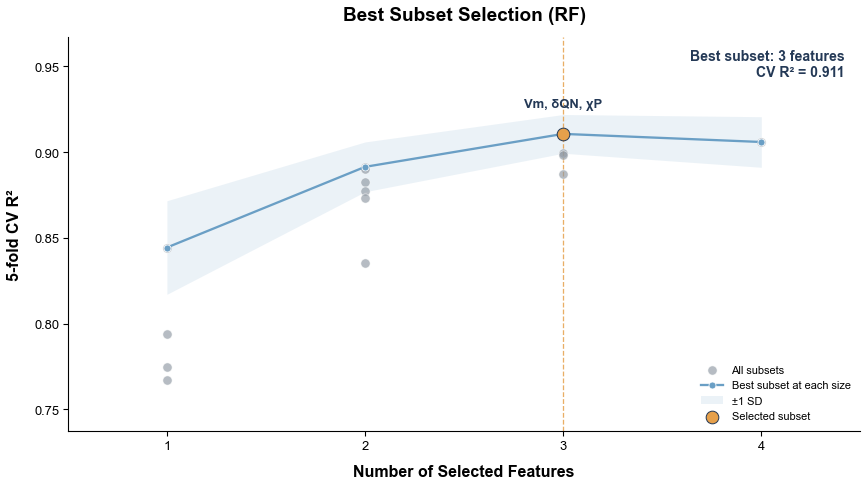


BEST SUBSET SELECTION COMPLETED
Recommended model  : RF
Input RFE features : 4
Evaluated subsets  : 15

Best subset size   : 3
Best CV R2         : 0.9107
Best CV RMSE       : 59.12 Hv
Best CV MAE        : 46.64 Hv

Final selected features:
['Vm', 'δQN', 'χP']

Saved files:
1. 06_BSS_Results.xlsx
2. 06_BSS_Performance.png


In [8]:
# ============================================================
# 06. FEATURE ENGINEERING - BEST SUBSET SELECTION
# Exhaustive Feature Subset Search
#
# Inputs:
#   Chap10_Data.xlsx
#   03_Model_Comparison_Results.xlsx
#   05_RFE_Results.xlsx
#
# Outputs:
#   06_BSS_Results.xlsx
#   06_BSS_Performance.png
#
# Description:
#   - Automatically load the recommended ML model
#   - Use features selected by RFE
#   - Evaluate all non-empty feature subsets
#   - Select the best subset using mean 5-fold CV R2
#   - Prefer fewer features and lower RMSE for tied scores
#   - Save selected features for final model development
# ============================================================


# ------------------------------------------------------------
# 1. Import Libraries
# ------------------------------------------------------------

import textwrap
from itertools import combinations
from math import comb

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import (
    train_test_split,
    KFold,
    cross_validate
)

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor,
    AdaBoostRegressor
)

from sklearn.tree import DecisionTreeRegressor
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from sklearn.neural_network import MLPRegressor

from xgboost import XGBRegressor


# ------------------------------------------------------------
# 2. General Settings
# ------------------------------------------------------------

INPUT_FILE = "Chap10_Data.xlsx"
MODEL_FILE = "03_Model_Comparison_Results.xlsx"
RFE_FILE = "05_RFE_Results.xlsx"

EXCEL_FILE = "06_BSS_Results.xlsx"
FIGURE_FILE = "06_BSS_Performance.png"

# Exhaustive search settings
MAX_COMBINATIONS = 50000
R2_TIE_TOLERANCE = 1e-10

# Computational settings
N_JOBS = -1
DPI = 600

# Figure settings
FIG_SIZE = (12.8, 7.2)

ALL_SUBSET_SIZE = 85
ALL_SUBSET_ALPHA = 0.65

FEATURE_LABEL_OFFSET = 24
FEATURE_WRAP_WIDTH = 28

# Colors
BLUE = "#6A9FC5"
ORANGE = "#E6A04B"
DARK_BLUE = "#243956"
GRAY = "#9099A3"

plt.rcParams.update({
    "font.family": "Arial",
    "font.size": 13,
    "axes.labelsize": 16,
    "axes.titlesize": 18,
    "xtick.labelsize": 13,
    "ytick.labelsize": 13,
    "axes.linewidth": 1.1,
    "xtick.direction": "out",
    "ytick.direction": "out",
    "xtick.major.size": 5,
    "ytick.major.size": 5,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.dpi": DPI
})


# ------------------------------------------------------------
# 3. Load Recommended Model Settings
# ------------------------------------------------------------

# Read the best-performing algorithm and experimental
# settings from Step 03 - Model Comparison.

model_info = pd.read_excel(
    MODEL_FILE,
    sheet_name="Best_Model"
)

MODEL_NAME = str(
    model_info.loc[0, "Model"]
).strip()

RANDOM_STATE = int(
    model_info.loc[0, "Random_State"]
)

TEST_SIZE = float(
    model_info.loc[0, "Test_Size"]
)

CV_FOLDS = int(
    model_info.loc[0, "CV_Folds"]
)

print("=" * 65)
print("06. BEST SUBSET SELECTION")
print("=" * 65)

print(f"Recommended model : {MODEL_NAME}")
print(f"Random state      : {RANDOM_STATE}")
print(f"Test size         : {TEST_SIZE}")
print(f"CV folds          : {CV_FOLDS}")

print("=" * 65)


# ------------------------------------------------------------
# 4. Load RFE-Selected Features
# ------------------------------------------------------------

# Read the final features obtained from Step 05 - RFE.

rfe_df = pd.read_excel(
    RFE_FILE,
    sheet_name="Selected_Features"
)

if "Feature" not in rfe_df.columns:
    raise ValueError(
        "The RFE results must contain a 'Feature' column."
    )

rfe_features = (
    rfe_df["Feature"]
    .dropna()
    .astype(str)
    .tolist()
)

if not rfe_features:
    raise ValueError(
        "No RFE-selected features were found."
    )

if len(rfe_features) != len(set(rfe_features)):
    raise ValueError(
        "Duplicate feature names detected."
    )

n_features = len(rfe_features)

# Total number of non-empty subsets
n_subsets = 2 ** n_features - 1

print("\nRFE-selected features:")
print(f"Number of features : {n_features}")
print(f"Total subsets      : {n_subsets:,}")
print(rfe_features)

# Prevent unexpectedly large exhaustive searches
if n_subsets > MAX_COMBINATIONS:
    raise ValueError(
        f"Exhaustive BSS requires {n_subsets:,} subsets, "
        f"exceeding MAX_COMBINATIONS={MAX_COMBINATIONS:,}. "
        "Reduce the input feature count or adjust the limit."
    )


# ------------------------------------------------------------
# 5. Load Dataset
# ------------------------------------------------------------

df = pd.read_excel(INPUT_FILE)

# First column: Vickers hardness (Hv)
# Remaining columns: Input features

target_col = df.columns[0]
all_feature_cols = list(df.columns[1:])

# Check that all RFE-selected features are available
missing_features = [
    feature
    for feature in rfe_features
    if feature not in all_feature_cols
]

if missing_features:
    raise ValueError(
        f"Features missing from dataset: {missing_features}"
    )

# Convert target and features to numerical values
y_all = pd.to_numeric(
    df[target_col],
    errors="coerce"
)

X_all = df[all_feature_cols].apply(
    pd.to_numeric,
    errors="coerce"
)

X_all = X_all.replace(
    [np.inf, -np.inf],
    np.nan
)

# Remove samples with missing target values
valid_mask = y_all.notna()

X = X_all.loc[valid_mask].copy()
y = y_all.loc[valid_mask].copy()

if len(X) < 20:
    raise ValueError(
        "Insufficient samples for Best Subset Selection."
    )


# ------------------------------------------------------------
# 6. Reproduce Train/Test Split
# ------------------------------------------------------------

# The same split as Model Comparison is reproduced.
# Only training data are used during subset evaluation.

X_train_all, X_test_all, y_train, y_test = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE
)

# Keep only RFE-selected features
X_train = X_train_all[rfe_features].copy()

if len(X_train) < CV_FOLDS * 2:
    raise ValueError(
        "Insufficient training samples for cross-validation."
    )

print("\nDataset information:")
print(f"Total samples         : {len(X)}")
print(f"Training samples      : {len(X_train)}")
print(f"Reserved test samples : {len(X_test_all)}")
print(f"Candidate features    : {len(rfe_features)}")


# ------------------------------------------------------------
# 7. Define Machine Learning Models
# ------------------------------------------------------------

# Reconstruct the selected algorithm using the same
# settings as Step 03 - Model Comparison.


def get_model(model_name):

    if model_name == "GDB":

        return GradientBoostingRegressor(
            random_state=RANDOM_STATE
        )

    elif model_name == "RF":

        return RandomForestRegressor(
            n_estimators=300,
            random_state=RANDOM_STATE,
            n_jobs=1
        )

    elif model_name == "XGB":

        return XGBRegressor(
            n_estimators=300,
            objective="reg:squarederror",
            random_state=RANDOM_STATE,
            n_jobs=1,
            verbosity=0
        )

    elif model_name == "ADB":

        return AdaBoostRegressor(
            n_estimators=100,
            random_state=RANDOM_STATE
        )

    elif model_name == "DT":

        return DecisionTreeRegressor(
            random_state=RANDOM_STATE
        )

    elif model_name == "SVM-lin":

        return SVR(
            kernel="linear"
        )

    elif model_name == "SVM-poly":

        return SVR(
            kernel="poly"
        )

    elif model_name == "SVM-rbf":

        return SVR(
            kernel="rbf"
        )

    elif model_name == "KNN":

        return KNeighborsRegressor(
            n_neighbors=5
        )

    elif model_name == "MLP":

        return MLPRegressor(
            hidden_layer_sizes=(64, 32),
            activation="relu",
            solver="adam",
            max_iter=3000,
            early_stopping=True,
            random_state=RANDOM_STATE
        )

    else:

        raise ValueError(
            f"Unsupported model: {model_name}"
        )


# ------------------------------------------------------------
# 8. Build Preprocessing Pipeline
# ------------------------------------------------------------

# Apply feature scaling only to models that require it.
# Imputation is performed within each CV training fold.

SCALE_MODELS = {
    "SVM-lin",
    "SVM-poly",
    "SVM-rbf",
    "KNN",
    "MLP"
}


def build_pipeline(model_name):

    steps = [
        ("imputer", SimpleImputer(strategy="median"))
    ]

    if model_name in SCALE_MODELS:

        steps.append(
            ("scaler", StandardScaler())
        )

    steps.append(
        ("model", get_model(model_name))
    )

    return Pipeline(steps)


# ------------------------------------------------------------
# 9. Cross-Validation Settings
# ------------------------------------------------------------

cv = KFold(
    n_splits=CV_FOLDS,
    shuffle=True,
    random_state=RANDOM_STATE
)

scoring = {
    "R2": "r2",
    "RMSE": "neg_root_mean_squared_error",
    "MAE": "neg_mean_absolute_error"
}


# ------------------------------------------------------------
# 10. Exhaustive Best Subset Selection
# ------------------------------------------------------------

# Evaluate every non-empty subset of the RFE-selected
# features using the recommended regression model.
#
# For n features, the total number of subsets is:
#   2^n - 1

results = []
subset_id = 0

for k in range(1, n_features + 1):

    num_current = comb(n_features, k)

    print(
        f"\nEvaluating {k}-feature subsets "
        f"({num_current:,} combinations)"
    )

    for subset in combinations(rfe_features, k):

        subset_id += 1
        subset = list(subset)

        X_subset = X_train[subset]

        pipeline = build_pipeline(MODEL_NAME)

        # Cross-validation on training data only
        cv_results = cross_validate(
            pipeline,
            X_subset,
            y_train,
            cv=cv,
            scoring=scoring,
            n_jobs=N_JOBS,
            error_score="raise"
        )

        r2_scores = cv_results["test_R2"]
        rmse_scores = -cv_results["test_RMSE"]
        mae_scores = -cv_results["test_MAE"]

        results.append({
            "Subset_ID": subset_id,
            "Number_of_Features": k,
            "Features": " | ".join(subset),

            "CV_R2_Mean": np.mean(r2_scores),
            "CV_R2_STD": np.std(r2_scores, ddof=1),

            "CV_RMSE_Mean": np.mean(rmse_scores),
            "CV_RMSE_STD": np.std(rmse_scores, ddof=1),

            "CV_MAE_Mean": np.mean(mae_scores),
            "CV_MAE_STD": np.std(mae_scores, ddof=1)
        })


# ------------------------------------------------------------
# 11. Identify the Best Feature Subset
# ------------------------------------------------------------

results_df = pd.DataFrame(results)

# Sort all subsets by predictive performance
results_df = results_df.sort_values(
    by=[
        "CV_R2_Mean",
        "Number_of_Features",
        "CV_RMSE_Mean"
    ],
    ascending=[False, True, True]
).reset_index(drop=True)

# Highest mean CV R2
best_r2 = results_df["CV_R2_Mean"].max()

# Identify subsets within the numerical tie tolerance
tie_candidates = results_df[
    results_df["CV_R2_Mean"]
    >= best_r2 - R2_TIE_TOLERANCE
].copy()

# Tie-breaking priorities:
# 1. Fewer features
# 2. Lower mean CV RMSE
# 3. Higher mean CV R2
tie_candidates = tie_candidates.sort_values(
    by=[
        "Number_of_Features",
        "CV_RMSE_Mean",
        "CV_R2_Mean"
    ],
    ascending=[True, True, False]
)

best_subset_row = tie_candidates.iloc[0]

best_subset_id = int(
    best_subset_row["Subset_ID"]
)

best_features = (
    best_subset_row["Features"]
    .split(" | ")
)

best_n = len(best_features)

best_cv_r2 = float(
    best_subset_row["CV_R2_Mean"]
)

best_cv_rmse = float(
    best_subset_row["CV_RMSE_Mean"]
)

best_cv_mae = float(
    best_subset_row["CV_MAE_Mean"]
)

# Mark the selected subset
results_df["Selected"] = (
    results_df["Subset_ID"] == best_subset_id
)

print("\n" + "=" * 65)
print("BEST SUBSET SELECTION RESULT")
print("=" * 65)

print(f"Best subset size : {best_n}")
print(f"Best CV R2       : {best_cv_r2:.4f}")
print(f"Best CV RMSE     : {best_cv_rmse:.2f} Hv")
print(f"Best CV MAE      : {best_cv_mae:.2f} Hv")
print(f"Selected features: {best_features}")


# ------------------------------------------------------------
# 12. Best Subset at Each Feature Count
# ------------------------------------------------------------

# Select the highest-scoring subset for each size.

best_by_size = (
    results_df
    .sort_values(
        by=[
            "Number_of_Features",
            "CV_R2_Mean",
            "CV_RMSE_Mean"
        ],
        ascending=[True, False, True]
    )
    .groupby(
        "Number_of_Features",
        as_index=False
    )
    .first()
    .sort_values("Number_of_Features")
    .reset_index(drop=True)
)

# Number of evaluated combinations at each subset size
subset_count_df = pd.DataFrame({
    "Number_of_Features": list(
        range(1, n_features + 1)
    ),
    "Number_of_Subsets": [
        comb(n_features, k)
        for k in range(1, n_features + 1)
    ]
})


# ------------------------------------------------------------
# 13. Save BSS Results to Excel
# ------------------------------------------------------------

# Summary information
summary_df = pd.DataFrame([{
    "Recommended_Model": MODEL_NAME,
    "Input_RFE_Features": n_features,
    "Total_Evaluated_Subsets": n_subsets,
    "Best_Subset_ID": best_subset_id,
    "Best_Subset_Size": best_n,

    "Best_CV_R2": best_cv_r2,
    "Best_CV_RMSE": best_cv_rmse,
    "Best_CV_MAE": best_cv_mae,

    "Random_State": RANDOM_STATE,
    "Test_Size": TEST_SIZE,
    "CV_Folds": CV_FOLDS,

    "Selection_Method": "Exhaustive Best Subset Selection"
}])

# Selected feature list for final model development
selected_features_df = pd.DataFrame({
    "Feature": best_features
})

with pd.ExcelWriter(
    EXCEL_FILE,
    engine="openpyxl"
) as writer:

    # Summary and selected model information
    summary_df.to_excel(
        writer,
        sheet_name="Summary",
        index=False
    )

    # Final selected features
    selected_features_df.to_excel(
        writer,
        sheet_name="Selected_Features",
        index=False
    )

    # Best subset for each feature count
    best_by_size.to_excel(
        writer,
        sheet_name="Best_By_Size",
        index=False
    )

    # Complete exhaustive search results
    results_df.to_excel(
        writer,
        sheet_name="All_Subsets",
        index=False
    )

    # Number of evaluated subsets
    subset_count_df.to_excel(
        writer,
        sheet_name="Subset_Count",
        index=False
    )

    # Format Excel worksheets
    for sheet in writer.sheets.values():

        sheet.freeze_panes = "B2"
        sheet.auto_filter.ref = sheet.dimensions

        for column_cells in sheet.columns:

            max_length = max(
                len(str(cell.value))
                if cell.value is not None else 0
                for cell in column_cells
            )

            column_letter = column_cells[0].column_letter

            sheet.column_dimensions[
                column_letter
            ].width = min(max_length + 3, 48)


# ------------------------------------------------------------
# 14. Create BSS Performance Plot
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=FIG_SIZE,
    facecolor="white"
)

# All evaluated subsets
x_subsets = results_df[
    "Number_of_Features"
].to_numpy(dtype=float)

y_subsets = results_df[
    "CV_R2_Mean"
].to_numpy(dtype=float)

# Plot all subsets without horizontal jitter
ax.scatter(
    x_subsets,
    y_subsets,
    s=ALL_SUBSET_SIZE,
    color=GRAY,
    alpha=ALL_SUBSET_ALPHA,
    edgecolors="white",
    linewidths=0.7,
    label="All subsets",
    zorder=2,
    rasterized=True
)


# ------------------------------------------------------------
# 15. Best Subset Curve
# ------------------------------------------------------------

plot_x = best_by_size[
    "Number_of_Features"
].to_numpy(dtype=int)

plot_y = best_by_size[
    "CV_R2_Mean"
].to_numpy(dtype=float)

plot_std = best_by_size[
    "CV_R2_STD"
].to_numpy(dtype=float)

# Best mean CV R2 at each feature count
ax.plot(
    plot_x,
    plot_y,
    "-o",
    color=BLUE,
    linewidth=2.3,
    markersize=7,
    markeredgecolor="white",
    markeredgewidth=0.8,
    label="Best subset at each size",
    zorder=4
)

# Cross-validation standard deviation region
ax.fill_between(
    plot_x,
    plot_y - plot_std,
    plot_y + plot_std,
    color=BLUE,
    alpha=0.13,
    linewidth=0,
    label="±1 SD",
    zorder=1
)


# ------------------------------------------------------------
# 16. Highlight the Selected Subset
# ------------------------------------------------------------

# Optimal subset marker
ax.scatter(
    best_n,
    best_cv_r2,
    s=160,
    color=ORANGE,
    edgecolor=DARK_BLUE,
    linewidth=1.0,
    zorder=6,
    label="Selected subset"
)

# Vertical line at optimal subset size
ax.axvline(
    best_n,
    linestyle="--",
    color=ORANGE,
    linewidth=1.3,
    alpha=0.85,
    zorder=1
)

# Display selected feature names above the optimal point
feature_text = ", ".join(best_features)

feature_text = "\n".join(
    textwrap.wrap(
        feature_text,
        width=FEATURE_WRAP_WIDTH,
        break_long_words=False,
        break_on_hyphens=False
    )
)

ax.annotate(
    feature_text,
    xy=(best_n, best_cv_r2),
    xytext=(0, FEATURE_LABEL_OFFSET),
    textcoords="offset points",
    ha="center",
    va="bottom",
    fontsize=13,
    fontweight="bold",
    color=DARK_BLUE,
    zorder=7
)

# Summary annotation
ax.text(
    0.98,
    0.97,
    f"Best subset: {best_n} features\n"
    f"CV R² = {best_cv_r2:.3f}",
    transform=ax.transAxes,
    ha="right",
    va="top",
    fontsize=14,
    color=DARK_BLUE,
    fontweight="bold"
)


# ------------------------------------------------------------
# 17. Figure Formatting
# ------------------------------------------------------------

ax.set_xlabel(
    "Number of Selected Features",
    fontsize=16,
    fontweight="bold",
    labelpad=12
)

ax.set_ylabel(
    "5-fold CV R²",
    fontsize=16,
    fontweight="bold",
    labelpad=12
)

ax.set_title(
    f"Best Subset Selection ({MODEL_NAME})",
    fontsize=19,
    fontweight="bold",
    pad=17
)

# Integer X-axis positions
ax.set_xlim(
    0.5,
    n_features + 0.5
)

ax.set_xticks(
    np.arange(1, n_features + 1)
)

# Automatic Y-axis limits
all_y = results_df[
    "CV_R2_Mean"
].to_numpy()

y_low = min(
    np.min(all_y),
    np.min(plot_y - plot_std)
)

y_high = max(
    np.max(all_y),
    np.max(plot_y + plot_std)
)

y_padding = max(
    0.03,
    (y_high - y_low) * 0.10
)

# Extra space for the selected feature annotation
ax.set_ylim(
    y_low - y_padding,
    y_high + max(y_padding, 0.045)
)

# Axis formatting
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.spines["left"].set_linewidth(1.1)
ax.spines["bottom"].set_linewidth(1.1)

ax.tick_params(
    axis="both",
    direction="out",
    length=5,
    width=1.1
)

ax.grid(False)

ax.legend(
    loc="lower right",
    frameon=False,
    fontsize=11
)

fig.subplots_adjust(
    left=0.10,
    right=0.96,
    bottom=0.14,
    top=0.90
)


# ------------------------------------------------------------
# 18. Save and Display
# ------------------------------------------------------------

fig.savefig(
    FIGURE_FILE,
    dpi=DPI,
    facecolor="white",
    bbox_inches="tight",
    pad_inches=0.03
)

plt.show()
plt.close(fig)


# ------------------------------------------------------------
# 19. Final Summary
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("BEST SUBSET SELECTION COMPLETED")
print("=" * 65)

print(f"Recommended model  : {MODEL_NAME}")
print(f"Input RFE features : {n_features}")
print(f"Evaluated subsets  : {n_subsets:,}")

print(f"\nBest subset size   : {best_n}")
print(f"Best CV R2         : {best_cv_r2:.4f}")
print(f"Best CV RMSE       : {best_cv_rmse:.2f} Hv")
print(f"Best CV MAE        : {best_cv_mae:.2f} Hv")

print("\nFinal selected features:")
print(best_features)

print("\nSaved files:")
print(f"1. {EXCEL_FILE}")
print(f"2. {FIGURE_FILE}")

print("=" * 65)

07. FINAL MODEL DEVELOPMENT
Recommended model : RF
Random state      : 42
Test size         : 0.2
CV folds          : 5
Search iterations : 40

Final selected features:
01. Vm
02. δQN
03. χP

Dataset information:
Total samples    : 300
Training samples : 240
Testing samples  : 60
Selected features: 3

HYPERPARAMETER OPTIMIZATION
Fitting 5 folds for each of 40 candidates, totalling 200 fits

Optimization completed.
Best CV R2: 0.9083

Best hyperparameters:
  model__bootstrap: True
  model__max_depth: 10
  model__max_features: 1.0
  model__min_samples_leaf: 3
  model__min_samples_split: 10
  model__n_estimators: 1040

FINAL MODEL PERFORMANCE
Train: R2=0.9575, RMSE=41.42, MAE=32.06
Test : R2=0.8968, RMSE=68.62, MAE=49.61
CV   : R2=0.9083

Optimized model saved: 07_Final_Model.joblib
Excel results saved: 07_Final_Model_Results.xlsx


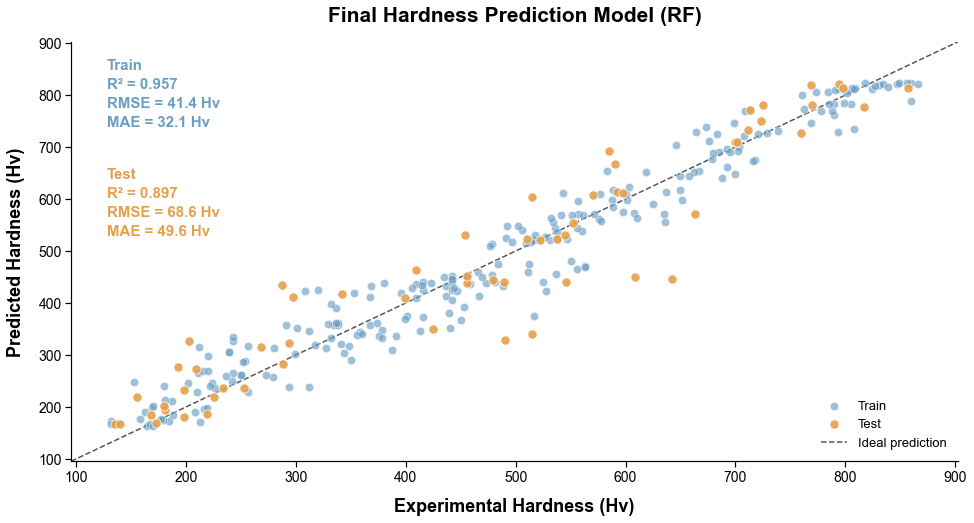


Performance figure saved: 07_Final_Model_Performance.png
Saved model successfully verified.

FINAL MODEL DEVELOPMENT COMPLETED
Algorithm       : RF
Input features  : 3
Best CV R2      : 0.9083
Train R2        : 0.9575
Test R2         : 0.8968

Selected features:
['Vm', 'δQN', 'χP']

Saved files:
1. 07_Final_Model.joblib
2. 07_Final_Model_Results.xlsx
3. 07_Final_Model_Performance.png


In [9]:
# ============================================================
# 07. MODEL DEVELOPMENT - FINAL HARDNESS PREDICTION MODEL
# Hyperparameter Optimization and Model Evaluation
#
# Inputs:
#   Chap10_Data.xlsx
#   03_Model_Comparison_Results.xlsx
#   06_BSS_Results.xlsx
#
# Outputs:
#   07_Final_Model.joblib
#   07_Final_Model_Results.xlsx
#   07_Final_Model_Performance.png
#
# Description:
#   - Load the recommended algorithm from Model Comparison
#   - Load the optimal feature subset from BSS
#   - Optimize hyperparameters using RandomizedSearchCV
#   - Evaluate training and independent testing performance
#   - Save the optimized model and prediction results
#   - Visualize experimental vs. predicted hardness
# ============================================================


# ------------------------------------------------------------
# 1. Import Libraries
# ------------------------------------------------------------

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from scipy.stats import randint, uniform, loguniform

from sklearn.model_selection import (
    train_test_split,
    KFold,
    RandomizedSearchCV,
    cross_validate
)

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.metrics import (
    r2_score,
    mean_squared_error,
    mean_absolute_error
)

from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor,
    AdaBoostRegressor
)

from sklearn.tree import DecisionTreeRegressor
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from sklearn.neural_network import MLPRegressor

from xgboost import XGBRegressor


# ------------------------------------------------------------
# 2. General Settings
# ------------------------------------------------------------

INPUT_FILE = "Chap10_Data.xlsx"
MODEL_FILE = "03_Model_Comparison_Results.xlsx"
BSS_FILE = "06_BSS_Results.xlsx"

MODEL_OUTPUT = "07_Final_Model.joblib"
EXCEL_OUTPUT = "07_Final_Model_Results.xlsx"
FIGURE_OUTPUT = "07_Final_Model_Performance.png"

# Hyperparameter optimization
N_ITER = 40
N_JOBS = -1

# Figure settings: 16:9
FIG_SIZE = (14, 7.875)
DPI = 600

# Colors
BLUE = "#6A9FC5"
ORANGE = "#E6A04B"
DARK_BLUE = "#243956"
GRAY = "#555555"

plt.rcParams.update({
    "font.family": "Arial",
    "font.size": 13,
    "axes.labelsize": 16,
    "axes.titlesize": 18,
    "xtick.labelsize": 13,
    "ytick.labelsize": 13,
    "axes.linewidth": 1.1,
    "xtick.direction": "out",
    "ytick.direction": "out",
    "xtick.major.size": 5,
    "ytick.major.size": 5,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.dpi": DPI
})


# ------------------------------------------------------------
# 3. Load Recommended Model Settings
# ------------------------------------------------------------

model_info = pd.read_excel(
    MODEL_FILE,
    sheet_name="Best_Model"
)

MODEL_NAME = str(
    model_info.loc[0, "Model"]
).strip()

RANDOM_STATE = int(
    model_info.loc[0, "Random_State"]
)

TEST_SIZE = float(
    model_info.loc[0, "Test_Size"]
)

CV_FOLDS = int(
    model_info.loc[0, "CV_Folds"]
)

print("=" * 65)
print("07. FINAL MODEL DEVELOPMENT")
print("=" * 65)

print(f"Recommended model : {MODEL_NAME}")
print(f"Random state      : {RANDOM_STATE}")
print(f"Test size         : {TEST_SIZE}")
print(f"CV folds          : {CV_FOLDS}")
print(f"Search iterations : {N_ITER}")

print("=" * 65)


# ------------------------------------------------------------
# 4. Load BSS-Selected Features
# ------------------------------------------------------------

feature_df = pd.read_excel(
    BSS_FILE,
    sheet_name="Selected_Features"
)

if "Feature" not in feature_df.columns:
    raise ValueError(
        "BSS results must contain a 'Feature' column."
    )

selected_features = (
    feature_df["Feature"]
    .dropna()
    .astype(str)
    .tolist()
)

if not selected_features:
    raise ValueError(
        "No BSS-selected features were found."
    )

if len(selected_features) != len(set(selected_features)):
    raise ValueError(
        "Duplicate selected features detected."
    )

print("\nFinal selected features:")

for i, feature in enumerate(selected_features, start=1):
    print(f"{i:02d}. {feature}")


# ------------------------------------------------------------
# 5. Load Dataset
# ------------------------------------------------------------

df = pd.read_excel(INPUT_FILE)

# First column: Vickers hardness (Hv)
# Remaining columns: Input features

target_col = df.columns[0]
feature_cols = list(df.columns[1:])

missing_features = [
    feature
    for feature in selected_features
    if feature not in feature_cols
]

if missing_features:
    raise ValueError(
        f"Features missing from dataset: {missing_features}"
    )

# Convert data to numerical values
y_all = pd.to_numeric(
    df[target_col],
    errors="coerce"
)

X_all = df[feature_cols].apply(
    pd.to_numeric,
    errors="coerce"
)

X_all = X_all.replace(
    [np.inf, -np.inf],
    np.nan
)

# Remove samples with invalid target values
valid_mask = y_all.notna() & np.isfinite(y_all)

X = X_all.loc[valid_mask].copy()
y = y_all.loc[valid_mask].copy()

if len(X) < 20:
    raise ValueError(
        "Insufficient samples for final model development."
    )


# ------------------------------------------------------------
# 6. Reproduce Train/Test Split
# ------------------------------------------------------------

# Use the same split as all previous model evaluation
# and feature engineering steps.
#
# The test set is excluded from hyperparameter optimization.

X_train_all, X_test_all, y_train, y_test = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE
)

X_train = X_train_all[selected_features].copy()
X_test = X_test_all[selected_features].copy()

if len(X_train) < CV_FOLDS * 2:
    raise ValueError(
        "Insufficient training samples for cross-validation."
    )

print("\nDataset information:")
print(f"Total samples    : {len(X)}")
print(f"Training samples : {len(X_train)}")
print(f"Testing samples  : {len(X_test)}")
print(f"Selected features: {len(selected_features)}")


# ------------------------------------------------------------
# 7. Define Model and Hyperparameter Search Space
# ------------------------------------------------------------

def get_model_and_parameters(model_name, random_state):

    if model_name == "RF":

        model = RandomForestRegressor(
            random_state=random_state,
            n_jobs=1
        )

        params = {
            "model__n_estimators": randint(200, 1201),
            "model__max_depth": [
                None, 5, 10, 15, 20, 30, 40
            ],
            "model__min_samples_split": [
                2, 4, 6, 8, 10
            ],
            "model__min_samples_leaf": [
                1, 2, 3, 4, 5
            ],
            "model__max_features": [
                "sqrt", "log2", 0.5, 0.7, 1.0
            ],
            "model__bootstrap": [True, False]
        }

    elif model_name == "GDB":

        model = GradientBoostingRegressor(
            random_state=random_state
        )

        params = {
            "model__n_estimators": randint(100, 801),
            "model__learning_rate": loguniform(0.01, 0.3),
            "model__max_depth": randint(2, 7),
            "model__min_samples_split": randint(2, 11),
            "model__min_samples_leaf": randint(1, 7),
            "model__subsample": uniform(0.6, 0.4),
            "model__max_features": [
                None, "sqrt", 0.7, 1.0
            ]
        }

    elif model_name == "XGB":

        model = XGBRegressor(
            objective="reg:squarederror",
            random_state=random_state,
            n_jobs=1,
            verbosity=0
        )

        params = {
            "model__n_estimators": randint(100, 1001),
            "model__max_depth": randint(2, 9),
            "model__learning_rate": loguniform(0.01, 0.3),
            "model__subsample": uniform(0.6, 0.4),
            "model__colsample_bytree": uniform(0.6, 0.4),
            "model__min_child_weight": randint(1, 11),
            "model__reg_alpha": loguniform(1e-4, 10),
            "model__reg_lambda": loguniform(0.1, 20)
        }

    elif model_name == "ADB":

        model = AdaBoostRegressor(
            random_state=random_state
        )

        params = {
            "model__n_estimators": randint(50, 601),
            "model__learning_rate": loguniform(0.01, 2),
            "model__loss": [
                "linear", "square", "exponential"
            ],
            "model__estimator": [
                DecisionTreeRegressor(
                    max_depth=depth,
                    random_state=random_state
                )
                for depth in [2, 3, 4, 5, 6]
            ]
        }

    elif model_name == "DT":

        model = DecisionTreeRegressor(
            random_state=random_state
        )

        params = {
            "model__max_depth": [
                None, 3, 5, 7, 10, 15, 20, 30
            ],
            "model__min_samples_split": randint(2, 21),
            "model__min_samples_leaf": randint(1, 11),
            "model__max_features": [
                None, "sqrt", "log2", 0.7, 1.0
            ],
            "model__ccp_alpha": [
                0.0, 0.001, 0.01, 0.1
            ]
        }

    elif model_name in {
        "SVM-lin", "SVM-poly", "SVM-rbf"
    }:

        kernel = {
            "SVM-lin": "linear",
            "SVM-poly": "poly",
            "SVM-rbf": "rbf"
        }[model_name]

        model = SVR(kernel=kernel)

        params = {
            "model__C": loguniform(0.1, 1000),
            "model__epsilon": loguniform(0.01, 10)
        }

        if kernel in {"poly", "rbf"}:
            params["model__gamma"] = loguniform(
                1e-4, 1
            )

        if kernel == "poly":
            params["model__degree"] = [2, 3, 4, 5]
            params["model__coef0"] = uniform(0, 2)

    elif model_name == "KNN":

        model = KNeighborsRegressor()

        params = {
            "model__n_neighbors": randint(2, 21),
            "model__weights": ["uniform", "distance"],
            "model__p": [1, 2],
            "model__leaf_size": randint(15, 61)
        }

    elif model_name == "MLP":

        model = MLPRegressor(
            random_state=random_state,
            max_iter=3000,
            early_stopping=True
        )

        params = {
            "model__hidden_layer_sizes": [
                (32,),
                (64,),
                (128,),
                (64, 32),
                (128, 64),
                (128, 64, 32),
                (256, 128)
            ],
            "model__activation": ["relu", "tanh"],
            "model__alpha": loguniform(1e-5, 1e-1),
            "model__learning_rate_init": loguniform(
                1e-4, 1e-2
            ),
            "model__batch_size": [16, 32, 64],
            "model__solver": ["adam"]
        }

    else:
        raise ValueError(
            f"Unsupported model: {model_name}"
        )

    return model, params


# ------------------------------------------------------------
# 8. Build Preprocessing Pipeline
# ------------------------------------------------------------

SCALE_MODELS = {
    "SVM-lin",
    "SVM-poly",
    "SVM-rbf",
    "KNN",
    "MLP"
}

base_model, param_distributions = (
    get_model_and_parameters(
        MODEL_NAME,
        RANDOM_STATE
    )
)

pipeline_steps = [
    ("imputer", SimpleImputer(strategy="median"))
]

if MODEL_NAME in SCALE_MODELS:

    pipeline_steps.append(
        ("scaler", StandardScaler())
    )

pipeline_steps.append(
    ("model", base_model)
)

pipeline = Pipeline(pipeline_steps)


# ------------------------------------------------------------
# 9. Hyperparameter Optimization
# ------------------------------------------------------------

cv = KFold(
    n_splits=CV_FOLDS,
    shuffle=True,
    random_state=RANDOM_STATE
)

search = RandomizedSearchCV(
    estimator=pipeline,
    param_distributions=param_distributions,
    n_iter=N_ITER,
    scoring="r2",
    cv=cv,
    n_jobs=N_JOBS,
    random_state=RANDOM_STATE,
    refit=True,
    verbose=1,
    return_train_score=True,
    error_score="raise"
)

print("\n" + "=" * 65)
print("HYPERPARAMETER OPTIMIZATION")
print("=" * 65)

search.fit(
    X_train,
    y_train
)

# The best estimator is refitted on the full training set.
best_model = search.best_estimator_

print("\nOptimization completed.")
print(f"Best CV R2: {search.best_score_:.4f}")

print("\nBest hyperparameters:")

for parameter, value in search.best_params_.items():
    print(f"  {parameter}: {value}")


# ------------------------------------------------------------
# 10. Final Predictions and Performance Metrics
# ------------------------------------------------------------

y_train_pred = best_model.predict(X_train)
y_test_pred = best_model.predict(X_test)


def calculate_metrics(y_true, y_pred):

    return {
        "R2": r2_score(y_true, y_pred),
        "RMSE": np.sqrt(
            mean_squared_error(y_true, y_pred)
        ),
        "MAE": mean_absolute_error(y_true, y_pred)
    }


train_metrics = calculate_metrics(
    y_train,
    y_train_pred
)

test_metrics = calculate_metrics(
    y_test,
    y_test_pred
)

print("\n" + "=" * 65)
print("FINAL MODEL PERFORMANCE")
print("=" * 65)

print(
    f"Train: R2={train_metrics['R2']:.4f}, "
    f"RMSE={train_metrics['RMSE']:.2f}, "
    f"MAE={train_metrics['MAE']:.2f}"
)

print(
    f"Test : R2={test_metrics['R2']:.4f}, "
    f"RMSE={test_metrics['RMSE']:.2f}, "
    f"MAE={test_metrics['MAE']:.2f}"
)

print(f"CV   : R2={search.best_score_:.4f}")


# ------------------------------------------------------------
# 11. Evaluate the Optimized Configuration Using CV
# ------------------------------------------------------------

# Evaluate the chosen hyperparameter configuration.
# These results are not nested-CV performance estimates.

cv_scoring = {
    "R2": "r2",
    "RMSE": "neg_root_mean_squared_error",
    "MAE": "neg_mean_absolute_error"
}

cv_results_final = cross_validate(
    best_model,
    X_train,
    y_train,
    cv=cv,
    scoring=cv_scoring,
    n_jobs=N_JOBS,
    error_score="raise"
)

cv_r2 = cv_results_final["test_R2"]
cv_rmse = -cv_results_final["test_RMSE"]
cv_mae = -cv_results_final["test_MAE"]

performance_df = pd.DataFrame([
    {
        "Dataset": "Train",
        "R2": train_metrics["R2"],
        "RMSE": train_metrics["RMSE"],
        "MAE": train_metrics["MAE"],
        "R2_STD": np.nan,
        "RMSE_STD": np.nan,
        "MAE_STD": np.nan
    },
    {
        "Dataset": "5-Fold CV",
        "R2": np.mean(cv_r2),
        "RMSE": np.mean(cv_rmse),
        "MAE": np.mean(cv_mae),
        "R2_STD": np.std(cv_r2, ddof=1),
        "RMSE_STD": np.std(cv_rmse, ddof=1),
        "MAE_STD": np.std(cv_mae, ddof=1)
    },
    {
        "Dataset": "Test",
        "R2": test_metrics["R2"],
        "RMSE": test_metrics["RMSE"],
        "MAE": test_metrics["MAE"],
        "R2_STD": np.nan,
        "RMSE_STD": np.nan,
        "MAE_STD": np.nan
    }
])


# ------------------------------------------------------------
# 12. Organize Prediction Results
# ------------------------------------------------------------

# Preserve the original Excel row numbers.
# Excel data start at row 2 because row 1 is the header.

train_predictions_df = pd.DataFrame({
    "Original_Row": X_train.index.to_numpy() + 2,
    "Dataset": "Train",
    "Actual_Hv": np.asarray(y_train),
    "Predicted_Hv": y_train_pred
})

test_predictions_df = pd.DataFrame({
    "Original_Row": X_test.index.to_numpy() + 2,
    "Dataset": "Test",
    "Actual_Hv": np.asarray(y_test),
    "Predicted_Hv": y_test_pred
})

predictions_df = pd.concat(
    [train_predictions_df, test_predictions_df],
    ignore_index=True
)

predictions_df["Residual_Hv"] = (
    predictions_df["Actual_Hv"]
    - predictions_df["Predicted_Hv"]
)

predictions_df["Absolute_Error_Hv"] = (
    predictions_df["Residual_Hv"].abs()
)

predictions_df = predictions_df.sort_values(
    by="Original_Row"
).reset_index(drop=True)


# ------------------------------------------------------------
# 13. Save Final Model
# ------------------------------------------------------------

# Save the complete pipeline, including preprocessing
# and the optimized prediction model.

joblib.dump(
    best_model,
    MODEL_OUTPUT
)

print(f"\nOptimized model saved: {MODEL_OUTPUT}")


# ------------------------------------------------------------
# 14. Prepare Excel Results
# ------------------------------------------------------------

summary_df = pd.DataFrame([{
    "Model": MODEL_NAME,
    "Target": str(target_col),
    "Number_of_Features": len(selected_features),
    "Training_Samples": len(X_train),
    "Testing_Samples": len(X_test),

    "Random_State": RANDOM_STATE,
    "Test_Size": TEST_SIZE,
    "CV_Folds": CV_FOLDS,
    "Search_Iterations": N_ITER,

    "Best_Search_CV_R2": search.best_score_,

    "Train_R2": train_metrics["R2"],
    "Train_RMSE": train_metrics["RMSE"],
    "Train_MAE": train_metrics["MAE"],

    "Test_R2": test_metrics["R2"],
    "Test_RMSE": test_metrics["RMSE"],
    "Test_MAE": test_metrics["MAE"]
}])

selected_features_df = pd.DataFrame({
    "Feature": selected_features
})

# Best hyperparameter configuration
best_params_df = pd.DataFrame({
    "Parameter": list(search.best_params_.keys()),
    "Value": [
        str(value)
        for value in search.best_params_.values()
    ]
})

# Full hyperparameter search results
search_results_df = pd.DataFrame(
    search.cv_results_
)

search_columns = [
    col
    for col in search_results_df.columns
    if (
        col.startswith("param_")
        or col in {
            "mean_test_score",
            "std_test_score",
            "rank_test_score",
            "mean_train_score",
            "std_train_score"
        }
    )
]

search_results_df = search_results_df[
    search_columns
].copy()

# Convert parameter values into Excel-compatible strings
for col in search_results_df.columns:

    if col.startswith("param_"):
        search_results_df[col] = (
            search_results_df[col].map(str)
        )

# Individual CV fold metrics
fold_metrics_df = pd.DataFrame({
    "Fold": np.arange(1, CV_FOLDS + 1),
    "CV_R2": cv_r2,
    "CV_RMSE": cv_rmse,
    "CV_MAE": cv_mae
})


# ------------------------------------------------------------
# 15. Save Results to Excel
# ------------------------------------------------------------

with pd.ExcelWriter(
    EXCEL_OUTPUT,
    engine="openpyxl"
) as writer:

    summary_df.to_excel(
        writer,
        sheet_name="Summary",
        index=False
    )

    performance_df.to_excel(
        writer,
        sheet_name="Performance",
        index=False
    )

    predictions_df.to_excel(
        writer,
        sheet_name="All_Predictions",
        index=False
    )

    selected_features_df.to_excel(
        writer,
        sheet_name="Selected_Features",
        index=False
    )

    best_params_df.to_excel(
        writer,
        sheet_name="Best_Hyperparameters",
        index=False
    )

    search_results_df.to_excel(
        writer,
        sheet_name="Hyperparameter_Search",
        index=False
    )

    fold_metrics_df.to_excel(
        writer,
        sheet_name="CV_Fold_Metrics",
        index=False
    )

    # Format Excel worksheets
    for sheet in writer.sheets.values():

        sheet.freeze_panes = "B2"
        sheet.auto_filter.ref = sheet.dimensions

        for column_cells in sheet.columns:

            max_length = max(
                len(str(cell.value))
                if cell.value is not None else 0
                for cell in column_cells
            )

            column_letter = column_cells[0].column_letter

            sheet.column_dimensions[
                column_letter
            ].width = min(max_length + 3, 48)

print(f"Excel results saved: {EXCEL_OUTPUT}")


# ------------------------------------------------------------
# 16. Create Train/Test Performance Plot
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=FIG_SIZE,
    facecolor="white"
)

actual_train = np.asarray(y_train)
actual_test = np.asarray(y_test)

all_actual = np.concatenate([
    actual_train,
    actual_test
])

all_predicted = np.concatenate([
    y_train_pred,
    y_test_pred
])

# Determine consistent limits for both axes
lower = min(
    np.min(all_actual),
    np.min(all_predicted)
)

upper = max(
    np.max(all_actual),
    np.max(all_predicted)
)

padding = max(
    10,
    (upper - lower) * 0.05
)

axis_min = lower - padding
axis_max = upper + padding


# ------------------------------------------------------------
# 17. Plot Experimental vs. Predicted Hardness
# ------------------------------------------------------------

# Ideal prediction line: y = x
ax.plot(
    [axis_min, axis_max],
    [axis_min, axis_max],
    color=GRAY,
    linestyle="--",
    linewidth=1.5,
    label="Ideal prediction",
    zorder=1
)

# Training samples
ax.scatter(
    actual_train,
    y_train_pred,
    s=70,
    color=BLUE,
    alpha=0.65,
    edgecolors="white",
    linewidths=0.7,
    label="Train",
    zorder=3
)

# Independent testing samples
ax.scatter(
    actual_test,
    y_test_pred,
    s=85,
    color=ORANGE,
    alpha=0.90,
    edgecolors="white",
    linewidths=0.8,
    label="Test",
    zorder=4
)


# ------------------------------------------------------------
# 18. Display Train and Test Performance Metrics
# ------------------------------------------------------------

# Group both metric blocks in the upper-left corner.

train_text = (
    "Train\n"
    f"R² = {train_metrics['R2']:.3f}\n"
    f"RMSE = {train_metrics['RMSE']:.1f} Hv\n"
    f"MAE = {train_metrics['MAE']:.1f} Hv"
)

test_text = (
    "Test\n"
    f"R² = {test_metrics['R2']:.3f}\n"
    f"RMSE = {test_metrics['RMSE']:.1f} Hv\n"
    f"MAE = {test_metrics['MAE']:.1f} Hv"
)

# Train metrics
ax.text(
    0.04,
    0.96,
    train_text,
    transform=ax.transAxes,
    ha="left",
    va="top",
    fontsize=15,
    fontweight="bold",
    color=BLUE,
    linespacing=1.45,
    zorder=8
)

# Test metrics directly below Train metrics
ax.text(
    0.04,
    0.70,
    test_text,
    transform=ax.transAxes,
    ha="left",
    va="top",
    fontsize=15,
    fontweight="bold",
    color=ORANGE,
    linespacing=1.45,
    zorder=8
)


# ------------------------------------------------------------
# 19. Figure Formatting
# ------------------------------------------------------------

ax.set_xlim(axis_min, axis_max)
ax.set_ylim(axis_min, axis_max)

# Use a rectangular plotting area for PowerPoint
ax.set_aspect("auto")

ax.set_xlabel(
    "Experimental Hardness (Hv)",
    fontsize=18,
    fontweight="bold",
    labelpad=13
)

ax.set_ylabel(
    "Predicted Hardness (Hv)",
    fontsize=18,
    fontweight="bold",
    labelpad=13
)

ax.set_title(
    f"Final Hardness Prediction Model ({MODEL_NAME})",
    fontsize=21,
    fontweight="bold",
    pad=20
)

# Axis formatting
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.spines["left"].set_linewidth(1.2)
ax.spines["bottom"].set_linewidth(1.2)

ax.tick_params(
    axis="both",
    direction="out",
    length=6,
    width=1.2,
    labelsize=14
)

ax.grid(False)


# ------------------------------------------------------------
# 20. Figure Legend
# ------------------------------------------------------------

# Reorder legend:
# Train -> Test -> Ideal prediction

handles, labels = ax.get_legend_handles_labels()

legend_order = [
    labels.index("Train"),
    labels.index("Test"),
    labels.index("Ideal prediction")
]

ax.legend(
    [handles[i] for i in legend_order],
    [labels[i] for i in legend_order],
    loc="lower right",
    frameon=False,
    fontsize=13
)

# Preserve the 16:9 figure dimensions
fig.subplots_adjust(
    left=0.09,
    right=0.97,
    bottom=0.15,
    top=0.89
)


# ------------------------------------------------------------
# 21. Save Performance Figure
# ------------------------------------------------------------

# Do not use bbox_inches="tight" here.
# This preserves the exact 16:9 image dimensions.

fig.savefig(
    FIGURE_OUTPUT,
    dpi=DPI,
    facecolor="white"
)

plt.show()
plt.close(fig)

print(f"\nPerformance figure saved: {FIGURE_OUTPUT}")


# ------------------------------------------------------------
# 22. Verify Saved Model
# ------------------------------------------------------------

# Reload the saved model and reproduce test predictions.

loaded_model = joblib.load(
    MODEL_OUTPUT
)

loaded_predictions = loaded_model.predict(
    X_test
)

if not np.allclose(
    loaded_predictions,
    y_test_pred
):
    raise ValueError(
        "Saved model predictions do not match "
        "the original predictions."
    )

print("Saved model successfully verified.")


# ------------------------------------------------------------
# 23. Final Summary
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("FINAL MODEL DEVELOPMENT COMPLETED")
print("=" * 65)

print(f"Algorithm       : {MODEL_NAME}")
print(f"Input features  : {len(selected_features)}")
print(f"Best CV R2      : {search.best_score_:.4f}")

print(f"Train R2        : {train_metrics['R2']:.4f}")
print(f"Test R2         : {test_metrics['R2']:.4f}")

print("\nSelected features:")
print(selected_features)

print("\nSaved files:")
print(f"1. {MODEL_OUTPUT}")
print(f"2. {EXCEL_OUTPUT}")
print(f"3. {FIGURE_OUTPUT}")

print("=" * 65)